# Counting cropland for a flood trigger in South Sudan: the whole analysis

Group 1, JBG060 2026, for ZOA International and the Zero Hunger Lab. This notebook runs the whole analysis behind the report, in order, from the data in this repository. Each step is a commented `.py` file in this folder. The notebook calls it the way the command line would (`python cropland/<step>.py <arguments>`) and shows what it prints, its tables and its figures.

**The question.** ZOA's flood trigger fires when a flood covers enough cropland. How much of ZOA's two areas (the five Aweil counties and Bor South) was cropland in 2025, and which cropland map can such a trigger trust there?

**The answer, in the order of this notebook.**
1. Seven public cropland maps give very different amounts of cropland in the same place (part 1).
2. Two of us labelled each box of a stratified random sample of 450 boxes (210 m) blind, from satellite images (part 2).
3. A two-question rule fitted on the calibration points (Rule 1) maps cropland better than the public maps here (parts 3 and 4).
4. The sample measures the cropland area with a 95% interval and scores every map on the held-out test points (part 4).
5. Laid under past floods, the choice of map decides whether a trigger fires (part 5).

**How to run.** Open this notebook from the `cropland/` folder and run all cells (10 to 25 minutes on a laptop, most of it in part 3). It needs the course data (README, section 2). With `RUN_EARTH_ENGINE = False` (the default) the steps that query Google Earth Engine are not repeated: their outputs are saved in the repository, and every later step is recomputed from them and from the labels. The labels are human judgements made with the labelling tool. They are data and are not redone.

| part | steps (files in `cropland/`) | what it gives |
|---|---|---|
| 0 | setup | paths, flags, a check that the inputs are there |
| 1 | `eda_maps.py`, `eda_figures.py`, `eda_labels.py`, `efficiency.py`, `eda_window.py` | the public maps compared (figures 1-11, 16 and 25), labeller agreement, sample size, key numbers |
| 2 | `00`-`06` | pilot, strata and sample, labels merged, features (figures 17, 22-24) |
| 3 | `07`, `12`, `08` | Rule 1 refitted and checked against the frozen file, other models, our map (figures 18, 19, 21) |
| 4 | `09` | the cropland area with a 95% interval, every map scored (figure 20) |
| 5 | `10`, `10b`, `10c` | flooded cropland in 2025, past floods 2000-2025, the trigger, the exposure table (figures 12, 13) |
| 6 | `11`, `sensitivity.py` | evaluation additions and robustness checks (figures 14, 15 and 26) |
| 7 | `national_map.py` | our map over the whole country (figure 27) |
| 8 | `14_dashboard.py` | the results dashboard |
| 9 | `test_cropland.py`, `test_evaluation.py` | checks of the estimators, rules and evaluation code |
| 10 | `key_results.py` | every number the report and the poster quote, with the file it comes from |

Outputs go to `cropland/results/` (scores, areas, floods), `deliverables/cropland_report/tables/` and `figures/` (every table and figure), and `deliverables/cropland_report/dashboard.html` and `maps/`.

## 0. Setup

`RUN_EARTH_ENGINE = True` also queries Earth Engine again for what it gave before: the public maps at the sample points (step 09), the 2025 flood overlay (step 10) and any missing EDA export. That needs a Google account, a Cloud project registered for Earth Engine and `earthengine authenticate` once (README, section 2). Providers can reprocess their collections, so a new query can differ slightly from our run of 12-14 Oct 2026.

In [1]:
import contextlib
import os
import platform
import runpy
import sys
import time
import warnings
from importlib.metadata import version
from io import BytesIO
from pathlib import Path

import numpy as np
import pandas as pd
import PIL.Image
from IPython.display import display
from IPython.display import Image as IPImage

RUN_EARTH_ENGINE = False                                  # True: query Earth Engine again (README, section 2)
os.environ.setdefault("CROPLAND_EE_PROJECT", "southsudan-509222")   # with True: your own Earth Engine project

HERE = Path.cwd()                                         # this notebook's folder, cropland/
assert (HERE / "common.py").exists(), "open the notebook from the cropland/ folder (Jupyter then runs it there)"
sys.path.insert(0, str(HERE))
RULE1 = HERE / "rule1_2026-10-12.json"                    # Rule 1, frozen on 12 Oct 2026 before any test label was read
RES = HERE / "results"
OUTPUTS = HERE.parent / "deliverables" / "cropland_report"   # figures, tables, maps and the dashboard


class RelativePaths:
    """Standard output that shows paths inside the repository relative to it, so no local path is saved."""
    root = str(HERE.parent) + os.sep

    def __init__(self, out):
        self.out = out

    def write(self, text):
        return self.out.write(text.replace(self.root, ""))

    def flush(self):
        self.out.flush()


def run(script, *args):
    """Run one step as `python cropland/<script> <args>` would, in its own namespace, and time it."""
    path = Path(script) if Path(script).is_absolute() else HERE / script
    sys.argv = [path.name, *map(str, args)]
    start = time.time()
    with contextlib.redirect_stdout(RelativePaths(sys.stdout)):
        runpy.run_path(str(path), run_name="__main__")
    shown = " ".join(Path(a).name if isinstance(a, Path) else str(a) for a in args)
    print(f"[{path.name} {shown}: {time.time() - start:.0f} s]")


def Image(path, width=1200):
    """IPython's Image of a saved figure, scaled to screen width so that this notebook stays small.

    The full-resolution PNG stays in deliverables/cropland_report/figures/."""
    im = PIL.Image.open(path).convert("RGB")
    if im.width > width:
        im = im.resize((width, round(im.height * width / im.width)), PIL.Image.LANCZOS)
    buf = BytesIO()
    im.quantize(colors=256).save(buf, format="PNG", optimize=True)
    return IPImage(data=buf.getvalue(), format="png")


def figure(name):
    """Show a figure as saved in deliverables/cropland_report/figures/."""
    display(Image(OUTPUTS / "figures" / f"{name}.png"))


import common as C
import eda_maps as D            # the EDA's numbers
import eda_figures as F         # every chart
import eda_labels as L          # agreement between labellers
import efficiency as E          # sample size
import evaluation as V          # interval, error analysis, trigger agreement
import report_figures as RF     # figures 17-26

pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 20)
warnings.filterwarnings("ignore", message="Degrees of freedom <= 0")   # a stratum with one point has no variance
D.TABLES.mkdir(parents=True, exist_ok=True)
AREA_NAME = {"aweil": "Aweil counties", "bor_south": "Bor South"}
TILE = {"aweil": "h20v08", "bor_south": "h21v08"}

assert (C.COURSE / "flood_masks").exists(), (
    f"course data not found (looked in {C.COURSE}): put data-JBG060-2026/ next to the repository "
    "or set CROPLAND_COURSE_DATA (README, section 2)")
HAVE_NATIONAL = (D.CACHE / "national.npz").exists()       # 51 MB, not in the zip (README, section 4.3)
HAVE_IMAGES = (HERE / "label_tool" / "img").is_dir()      # the labelling images, shared as a zip; only figure 24 needs them
packages = [l.split("==")[0] for l in (HERE / "requirements-cropland.txt").read_text().splitlines() if "==" in l]
print(f"Python {platform.python_version()}:", ", ".join(f"{p} {version(p)}" for p in packages))
print("course data:", os.path.relpath(C.COURSE, HERE.parent), "(relative to the repository)")
print("saved Earth Engine outputs:", ", ".join(sorted(p.name for p in D.CACHE.glob("*.np*"))))
print("national.npz:", "yes" if HAVE_NATIONAL else "no: part 1 reads the national flood rows back from its saved table")
print("labelling images:", "yes" if HAVE_IMAGES else "no: figure 24 stays as saved")
print("Earth Engine:", f"on, project {os.environ['CROPLAND_EE_PROJECT']}" if RUN_EARTH_ENGINE else "off, saved outputs are used")

Python 3.12.5: earthengine-api 1.7.46, geopandas 1.2.0, pandas 2.2.3, numpy 2.1.2, scipy 1.14.1, scikit-learn 1.5.2, matplotlib 3.9.2, rasterio 1.5.0, pyarrow 24.0.0, shapely 2.1.2, pyogrio 0.13.0, pyproj 3.8.0, affine 3.0.1, joblib 1.4.2, pillow 11.0.0, nbformat 5.11.1, nbclient 0.11.0, ipykernel 6.29.5
course data: ..\data-JBG060-2026 (relative to the repository)
saved Earth Engine outputs: national.npz, national_rule1_1km.npz, stab_dw_aweil.npz, stab_dw_bor_south.npz, stab_esri_aweil.npz, stab_esri_bor_south.npz, window_aweil_s020.npz, zoa_aweil.npz, zoa_bor_south.npz
national.npz: yes
labelling images: yes
Earth Engine: off, saved outputs are used


## 1. The public maps (exploratory data analysis)

The data understanding behind the report. What it shows:

1. **How much.** The 7 maps we stratify on (plus ASAP, the course data) give very different amounts of cropland.
2. **Where.** Where two maps call crop, it is rarely the same land. **What the papers found** for the same maps elsewhere in Africa (1.2b), including Esri's F1 of 0 in Mali.
3. **National pattern.** The maps do not follow the FAO/WFP crop assessment (CFSAM) from state to state.
4. **Time.** The same product changes a lot from one year to the next.
5. **Flood trigger.** The choice of map moves "flooded cropland", and so a trigger, by one to two orders of magnitude.
6. **Labellers, sample size and the interval.** How well two of us agree, how many labelled points a yearly check needs, and whether the 95% interval holds (simulation, 1.9b).

The counts of every map come from Earth Engine exports saved in `raw_data/cropland/eda/`. Every figure has a CSV twin in `deliverables/cropland_report/tables/`.

### 1.0 Earth Engine exports (once)

Every map is turned into crop / not crop exactly as for the strata (`common.public_maps`, following Kerner et al. 2024), evaluated on a fine grid (~10 m in the study areas, ~15 m nationally, ~19 m for the yearly series) and counted inside every cell of the NASA flood grid (1/480 degree, ~232 m). Counting on the fine grid matters: reading a map at a coarse scale uses Earth Engine's pyramids, which drop a rare class such as crop. Because the counts sit on the flood grid, the flood overlay later is an exact join.

Check: the stratum areas this gives for Aweil (0 maps 94.97%, 1-2 maps 4.71%, 3+ maps 0.32%) are the ones in `strata_areas.csv`, which was computed independently at 10 m for the sample.

In [2]:
needed = [f"zoa_{a}" for a in D.C.AREAS] + ["national"] + [f"stab_{p}_{a}" for p in ("esri", "dw") for a in D.C.AREAS]
missing = [n for n in needed if not (D.CACHE / f"{n}.npz").exists()]
if missing and RUN_EARTH_ENGINE:
    ee = D.ee_init()
    parts = {n.split("_")[0] for n in missing}
    D.export(ee, parts)        # batch tasks: follow them with D.status(ee), then run D.download(ee, missing)
print("missing exports:", missing or "none")

missing exports: none


### 1.1 How much cropland? Seven maps, seven answers

Crop share of the land per map and county. Reference lines: the CFSAM cereal harvested area (a modelled figure: population x share of households farming x area per farming household, traditional sector only, cereals only) and, nationally, FAOSTAT arable land. Neither is ground truth; they show the order of magnitude official statistics work with.

In [3]:
cells = {a: D.zoa_cells(a) for a in D.C.AREAS}
shares = pd.concat([D.crop_shares(df).assign(area=a) for a, df in cells.items()])
shares.to_csv(D.TABLES / "crop_share_by_county.csv", index=False)
shares.pivot_table(index="map", columns="unit", values="crop_pct").round(2)

unit,Aweil Centre,Aweil East,Aweil North,Aweil South,Aweil West,Bor South,all counties
map,,,,,,,
asap_v04,0.04,3.00,0.67,1.76,0.51,0.01,0.97
deafrica_2019,0.22,4.37,1.85,2.31,1.62,0.00,1.77
dynamicworld_2022,0.15,2.63,0.20,1.13,0.52,21.34,0.79
dynamicworld_2025,0.04,0.69,0.08,0.15,0.21,8.99,0.22
esri_2022,0.16,1.28,0.19,0.10,0.34,0.06,0.42
esri_2025,0.26,1.04,0.14,0.07,0.30,0.03,0.39
gfsad_2015,0.13,4.48,1.52,5.34,1.80,0.22,1.92
glad_2019,0.33,1.66,0.88,0.80,1.85,0.25,1.00
worldcereal_2021,0.04,3.09,0.70,1.82,0.54,0.01,1.00


In [4]:
nat = D.national() if HAVE_NATIONAL else None      # national.npz: only the national flood rows of 1.5 need it
cache = D.CACHE / "national_by_county.pkl"
cty = pd.read_pickle(cache) if cache.exists() else D.national_by_county(nat)
cty.to_pickle(cache)
cty.to_csv(D.TABLES / "national_crop_by_county.csv", index=False)
maps = D.MAPS + D.EXTRA + ["asap_v04"]
land = cty.land_ha.sum()
national = pd.DataFrame({"crop_Mha": cty[maps].sum() / 1e6, "crop_pct_of_land": 100 * cty[maps].sum() / land})
national.to_csv(D.TABLES / "national_crop_share.csv")
print(f"land: {land / 1e6:.2f} Mha (incl. Abyei)")
national.round(3)

land: 64.27 Mha (incl. Abyei)


,crop_Mha,crop_pct_of_land
worldcover_2021,0.243,0.378
glad_2019,0.397,0.618
deafrica_2019,0.872,1.357
worldcereal_2021,0.439,0.683
esri_2025,0.223,0.347
dynamicworld_2025,1.797,2.796
gfsad_2015,0.738,1.147
esri_2022,0.179,0.278
dynamicworld_2022,2.523,3.925
asap_v04,0.407,0.634


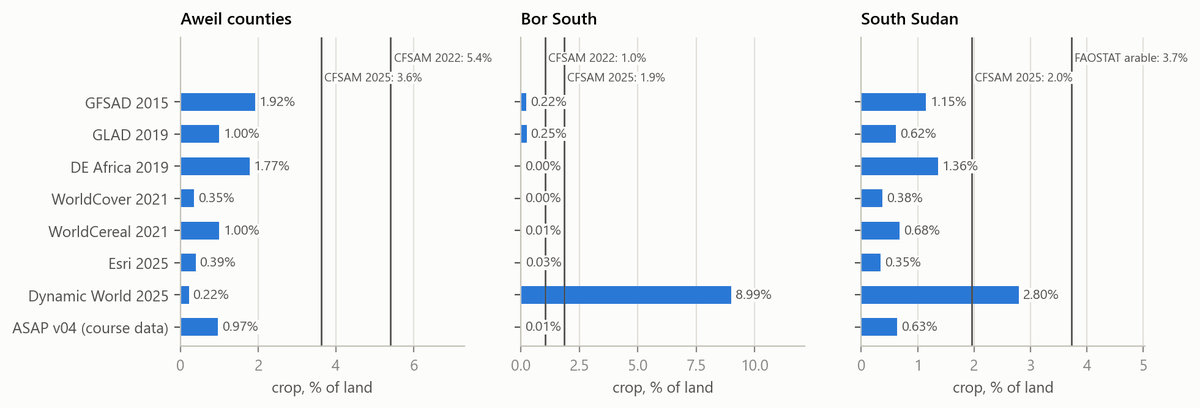

In [5]:
ref = pd.read_csv("reference_statistics.csv")
refn = pd.read_csv("reference_national.csv").set_index(["source", "year", "item"]).value
land_area = {a: float((df.inside * df.ha).sum()) for a, df in cells.items()}
county = ref[ref.level == "county"]
cfsam = {(a, y): county[(county.year == y) & county.name.str.startswith("Aweil" if a == "aweil" else "Bor")].cereal_harvested_ha.sum()
         for a in D.C.AREAS for y in (2022, 2025)}
refs = {AREA_NAME[a]: [(f"CFSAM {y}", 100 * cfsam[(a, y)] / land_area[a]) for y in (2025, 2022)] for a in D.C.AREAS}
refs["South Sudan"] = [("CFSAM 2025", 100 * refn[("CFSAM", 2025, "cereal harvested area")] / land),
                       ("FAOSTAT arable", 100 * refn[("FAOSTAT", 2022, "arable land")] / land)]
panels = {AREA_NAME[a]: shares[(shares.area == a) & shares.unit.isin(["all counties", "Bor South"])].set_index("map").crop_pct
          for a in D.C.AREAS}
panels["South Sudan"] = national.crop_pct_of_land
pd.DataFrame([{"panel": k, "line": l, "pct_of_land": float(v)} for k, vs in refs.items() for l, v in vs]).to_csv(D.TABLES / "reference_lines.csv", index=False)
display(Image(F.crop_share(panels, refs)))

The same 6 km window north of Aweil town in every map (figure 16; `eda_window.py fetch` saved the map tiles once from Earth Engine).

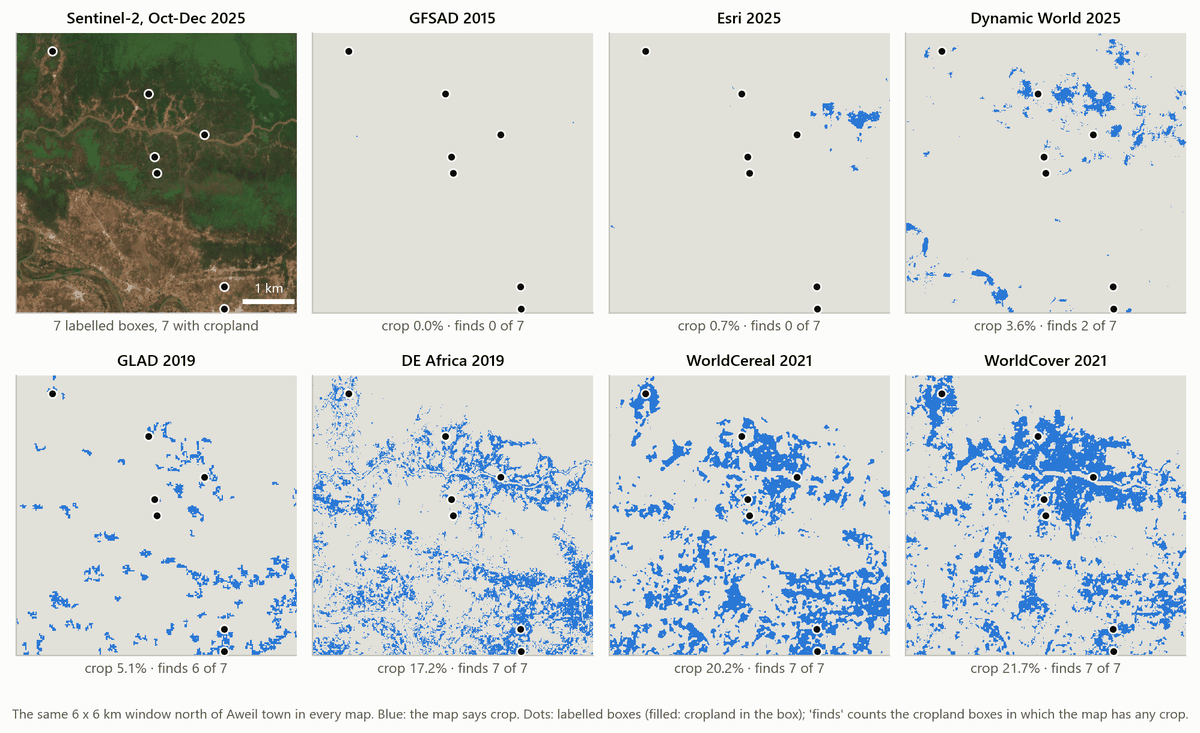

In [6]:
import eda_window
display(Image(eda_window.figure()))

### 1.2 Where? The maps hardly agree on which land is crop

Two views. The share of land called crop by at least *k* of the 7 maps (Kerner et al. 2024, Table 2, found unanimous crop on under 0.5% of every country they studied). And, for every two maps, the overlap of their crop class (intersection over union, IoU). Pixel agreement, the measure Kerner et al. report, looks high only because most land is "not crop" in every map; it is saved too.

,0 maps,1 maps,2 maps,3 maps,4 maps,5 maps,6 maps,7 maps
Aweil Centre,99.123,0.741,0.122,0.014,0.001,0.000,0.000,0.0
Aweil East,88.209,8.653,2.238,0.712,0.165,0.021,0.003,0.0
Aweil North,95.637,3.456,0.673,0.191,0.040,0.003,0.000,0.0
Aweil South,91.631,6.182,1.495,0.530,0.139,0.021,0.000,0.0
Aweil West,94.760,4.075,0.926,0.195,0.040,0.003,0.000,0.0
all counties,94.966,3.822,0.890,0.257,0.058,0.007,0.001,0.0
Bor South,90.560,9.373,0.063,0.004,0.000,0.000,0.000,0.0
South Sudan,94.517,4.517,0.542,0.144,0.116,0.155,0.009,0.0


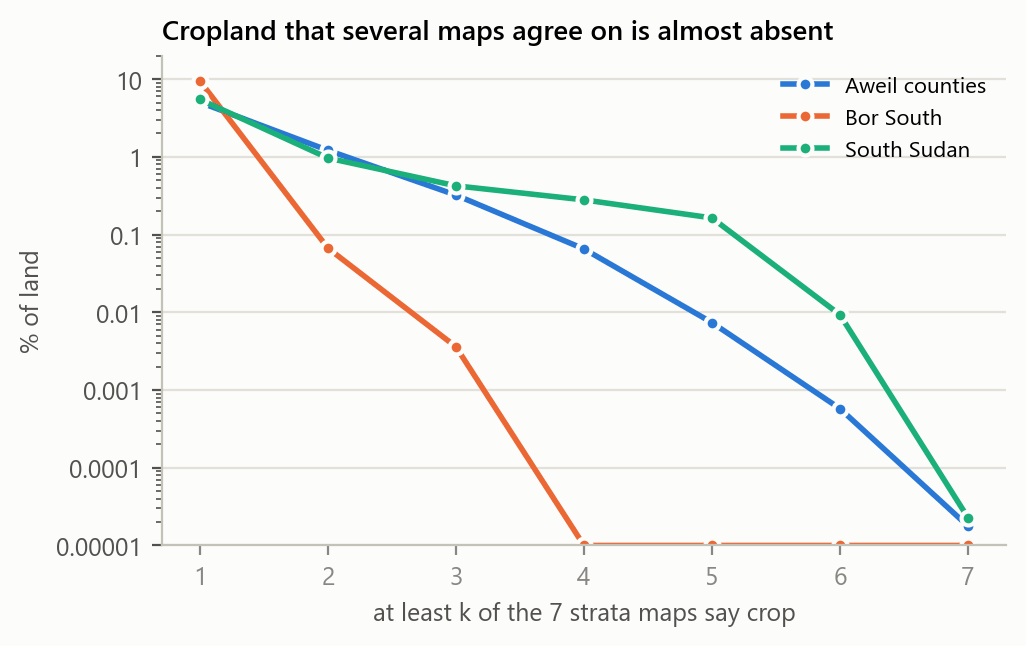

In [7]:
agree = {AREA_NAME[a]: D.agreement(df) for a, df in cells.items()}
agree["South Sudan"] = pd.DataFrame([100 * cty[[f"agree_{k}" for k in range(8)]].sum().to_numpy() / land],
                                    index=["South Sudan"], columns=[f"{k} maps" for k in range(8)])
agree_tab = pd.concat(agree.values())
agree_tab.to_csv(D.TABLES / "agreement_share_of_land.csv")
rows = {"Aweil counties": agree_tab.loc["all counties"], "Bor South": agree_tab.loc["Bor South"],
        "South Sudan": agree_tab.loc["South Sudan"]}
curves = {k: [v.iloc[j:].sum() for j in range(1, 8)] for k, v in rows.items()}
pd.DataFrame(curves, index=[f">= {j} maps" for j in range(1, 8)]).to_csv(D.TABLES / "agreement_at_least_k.csv")
display(agree_tab.round(3))
display(Image(F.agreement_curves(curves)))

Aweil counties: IoU 0.01-0.16, pixel agreement 0.967-0.995
Bor South: IoU 0.00-0.10, pixel agreement 0.908-1.000


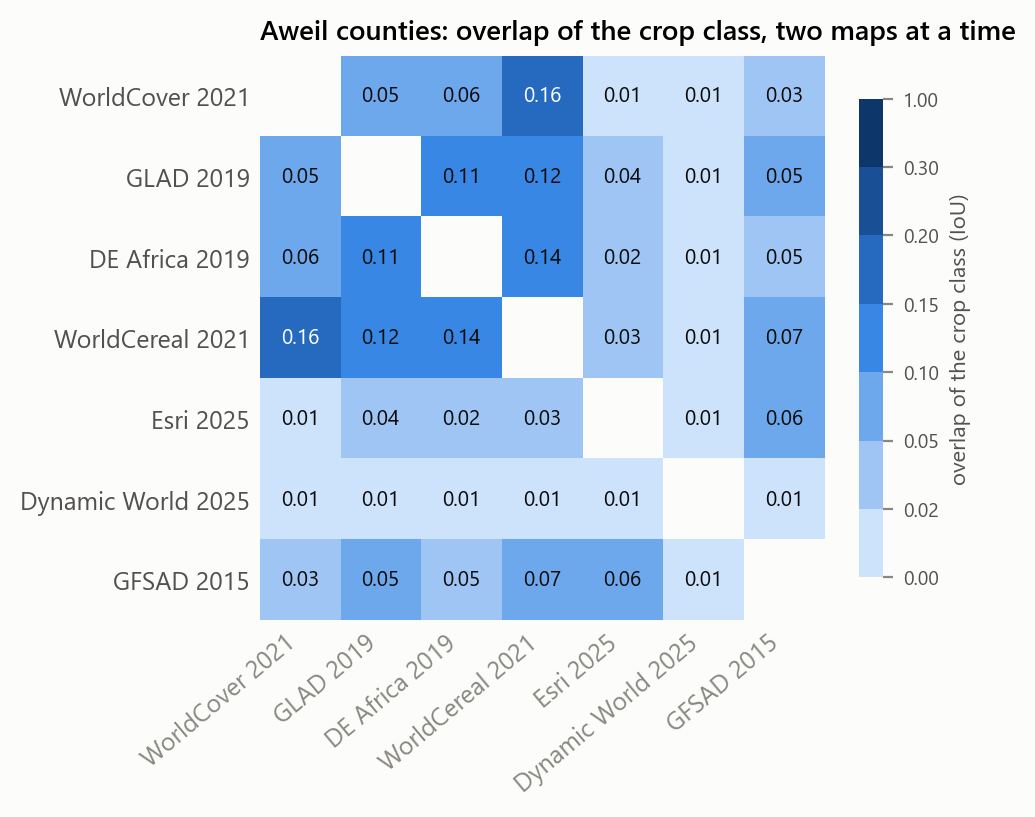

In [8]:
for a, df in cells.items():
    iou, kap, agr = D.pairwise(df)
    iou.to_csv(D.TABLES / f"pairwise_iou_{a}.csv")
    kap.to_csv(D.TABLES / f"pairwise_kappa_{a}.csv")
    agr.to_csv(D.TABLES / f"pairwise_pixel_agreement_{a}.csv")
    off = ~np.eye(len(iou), dtype=bool)
    print(f"{AREA_NAME[a]}: IoU {np.nanmin(iou.values[off]):.2f}-{np.nanmax(iou.values[off]):.2f}, "
          f"pixel agreement {np.nanmin(agr.values[off]):.3f}-{np.nanmax(agr.values[off]):.3f}")
iou_aweil = pd.read_csv(D.TABLES / "pairwise_iou_aweil.csv", index_col=0)
display(Image(F.pairwise_iou(iou_aweil, "Aweil counties: overlap of the crop class, two maps at a time", "03_pairwise_iou_aweil")))

### 1.2b What the two papers found for these maps

Kerner et al. (2024, Table 1) and Adebayo et al. (2026, Table 3) scored six of our seven strata maps (all but WorldCereal) and ASAP against labelled points in 8 and 6 African countries. Neither covers South Sudan. The values are transcribed, with table and page, in `reference_accuracy_literature.csv`; as a check, F1 matches the harmonic mean of precision and recall in every country row.

Two lessons for us:

1. **Accuracy misleads when crop is rare.** In Mali (2% of the points are crop, the case most like Aweil) Esri reaches 0.97 accuracy with F1 = 0: it calls no point crop. So we report precision, recall and F1 with standard errors, as both papers do, never accuracy alone.
2. **Low recall elsewhere, little crop here.** The maps that miss most crop in the papers' countries (lowest recall) are the ones that show the least crop in Aweil. In Bor South the pattern breaks: Dynamic World, with the lowest published recall, shows the most crop there. Published scores do not predict that local failure; only local labels can.

Our own scores for the same maps, on our test points, are in part 4 (`09_score.py`).

,kerner_mean_f1,kerner_f1_lowest,kerner_f1_lowest_country,kerner_f1_highest,kerner_f1_mali,kerner_accuracy_mali,kerner_mean_precision,kerner_mean_recall,adebayo_mean_f1,adebayo_mean_recall,aweil_crop_pct,bor_south_crop_pct
map,,,,,,,,,,,,
asap_v04,0.52,0.21,Mali,0.74,0.21,0.95,0.47,0.69,NaN,NaN,0.97,0.01
deafrica_2019,0.63,0.43,Uganda,0.85,0.46,0.96,0.56,0.81,0.62,0.73,1.77,0.00
dynamicworld_2025,0.34,0.12,Mali,0.63,0.12,0.94,0.63,0.30,0.34,0.27,0.22,8.99
esri_2025,0.43,0.00,Mali,0.75,0.00,0.97,0.63,0.38,0.49,0.40,0.39,0.03
gfsad_2015,0.58,0.15,Mali,0.76,0.15,0.91,0.51,0.74,NaN,NaN,1.92,0.22
glad_2019,0.65,0.33,Mali,0.75,0.33,0.96,0.68,0.68,0.64,0.66,1.00,0.25
worldcover_2021,0.65,0.43,Kenya,0.82,0.43,0.95,0.72,0.65,NaN,NaN,0.35,0.00


,Kerner recall (7 maps),Adebayo recall (4 maps)
Aweil counties,0.89,1.0
Bor South,-0.39,-0.8


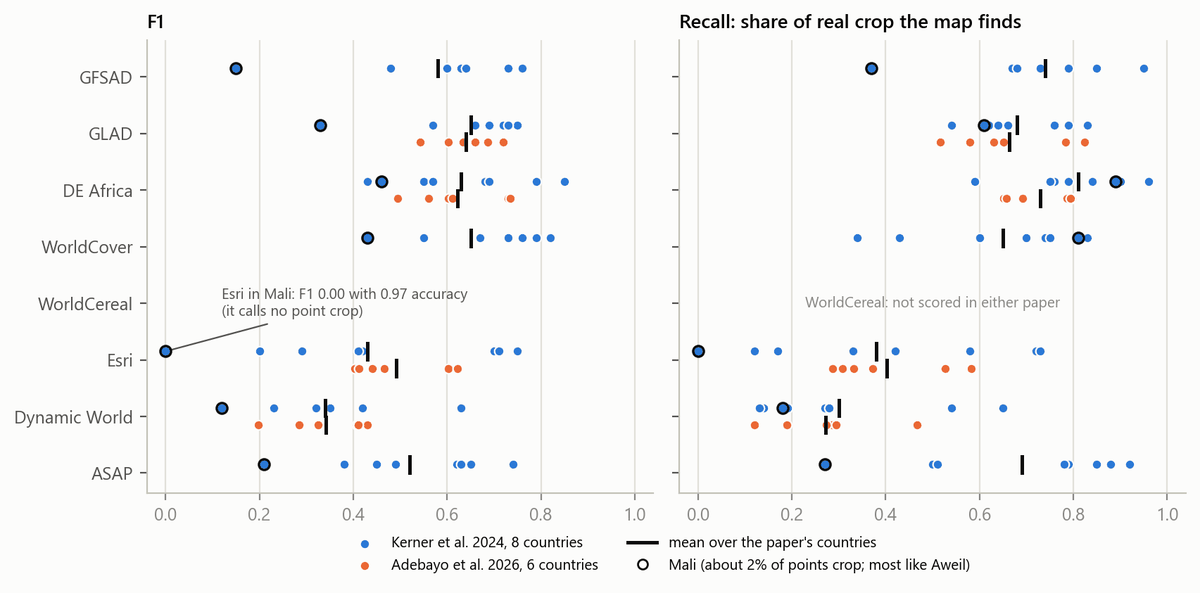

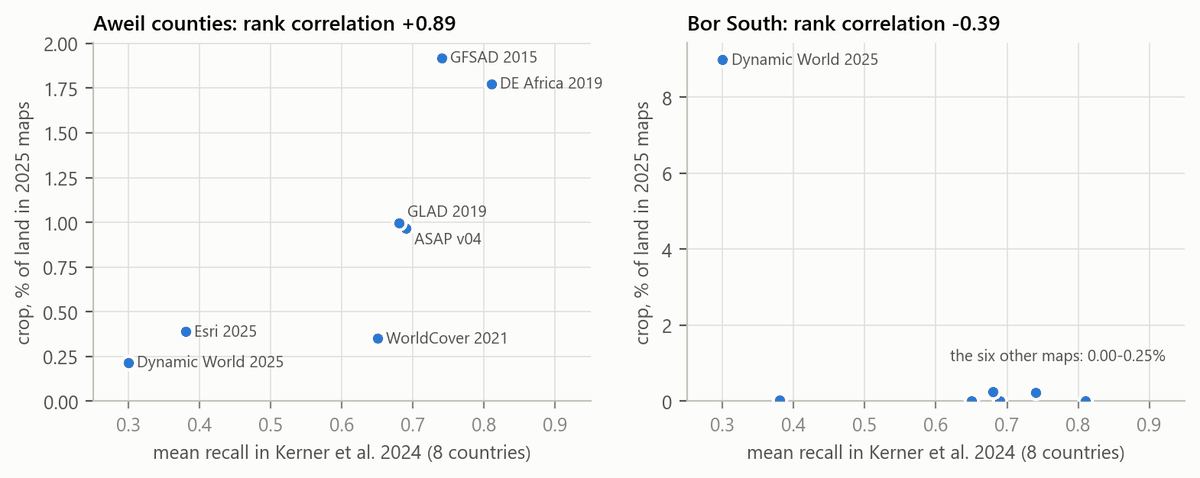

In [9]:
from scipy.stats import spearmanr
lit = pd.read_csv("reference_accuracy_literature.csv")
ours = {"esri": "esri_2025", "dynamicworld": "dynamicworld_2025", "deafrica": "deafrica_2019", "worldcover": "worldcover_2021",
        "gfsad": "gfsad_2015", "glad": "glad_2019", "asap": "asap_v04"}
k = lit[(lit.source == "Kerner et al. 2024") & lit["map"].isin(ours)]
a = lit[(lit.source == "Adebayo et al. 2026") & lit["map"].isin(ours)]
per = lambda t, metric: t[(t.metric == metric) & (t.country != "Mean")].pivot(index="map", columns="country", values="value")
f1k = per(k, "f1")
pub = pd.DataFrame({
    "kerner_mean_f1": k[(k.metric == "f1") & (k.country == "Mean")].set_index("map").value,
    "kerner_f1_lowest": f1k.min(axis=1), "kerner_f1_lowest_country": f1k.idxmin(axis=1),
    "kerner_f1_highest": f1k.max(axis=1), "kerner_f1_mali": f1k["Mali"],
    "kerner_accuracy_mali": per(k, "accuracy")["Mali"],
    "kerner_mean_precision": k[(k.metric == "precision") & (k.country == "Mean")].set_index("map").value,
    "kerner_mean_recall": k[(k.metric == "recall") & (k.country == "Mean")].set_index("map").value,
    "adebayo_mean_f1": a[(a.metric == "f1") & (a.country == "Mean")].set_index("map").value,
    "adebayo_mean_recall": a[(a.metric == "recall") & (a.country == "Mean")].set_index("map").value,
}).rename(index=ours)
aw = panels["Aweil counties"]
bs = panels["Bor South"]
pub["aweil_crop_pct"] = aw.reindex(pub.index)
pub["bor_south_crop_pct"] = bs.reindex(pub.index)
pub.to_csv(D.TABLES / "published_accuracy_of_our_maps.csv")
rho = pd.DataFrame({src: {area: spearmanr(pub[col].dropna(), pub.loc[pub[col].notna(), crop]).correlation
                          for area, crop in (("Aweil counties", "aweil_crop_pct"), ("Bor South", "bor_south_crop_pct"))}
                    for src, col in (("Kerner recall (7 maps)", "kerner_mean_recall"), ("Adebayo recall (4 maps)", "adebayo_mean_recall"))})
rho.to_csv(D.TABLES / "published_recall_vs_crop_share_rank_correlation.csv")
display(pub.round(2))
display(rho.round(2))
display(Image(F.published_accuracy(lit)))
display(Image(F.recall_vs_share(pd.DataFrame({"recall": pub.kerner_mean_recall, "aweil": pub.aweil_crop_pct,
                                              "bor_south": pub.bor_south_crop_pct}))))

### 1.3 The national pattern does not follow the crop assessment

Crop area per state and map against CFSAM's cereal harvested area. CFSAM's Pibor and Ruweng administrative areas are added to Jonglei and Unity (our 10-state boundaries). CFSAM covers the traditional smallholder sector only, so mechanised schemes (Upper Nile, around Renk) are missing from it. A high rank correlation would mean a map puts more crop where CFSAM does.

,worldcover_2021,glad_2019,deafrica_2019,worldcereal_2021,esri_2025,dynamicworld_2025,gfsad_2015,esri_2022,dynamicworld_2022,asap_v04,cfsam_2025_kha,cfsam_2022_kha
state,,,,,,,,,,,,
Abyei Region,2.0,1.6,15.1,1.9,0.4,2.7,7.5,0.6,4.8,1.9,7.005,7.964
Central Equatoria,2.0,61.3,2.1,11.2,10.3,11.5,117.0,7.3,90.8,10.2,120.600,82.619
Eastern Equatoria,14.0,30.5,96.8,159.5,59.7,357.6,21.2,32.2,800.8,114.1,155.634,133.950
Jonglei,0.1,3.8,3.3,0.4,8.4,624.9,137.3,10.6,784.3,0.4,91.539,63.378
Lakes,1.2,32.9,0.5,5.4,25.1,13.7,83.9,27.6,33.7,5.1,186.953,161.687
Northern Bahr el Ghazal,10.8,30.7,54.7,30.8,12.0,6.7,59.2,13.1,24.5,29.8,111.530,166.843
Unity,2.3,7.6,20.3,7.6,25.2,136.5,8.8,24.5,136.3,7.4,27.461,16.912
Upper Nile,184.1,170.7,550.3,180.5,62.6,626.5,27.7,41.8,605.2,180.8,88.816,48.454
Warrap,19.8,39.3,118.3,34.2,11.4,9.9,205.1,11.6,20.6,33.4,181.463,179.533


,2022,2025
worldcover_2021,0.16,-0.15
glad_2019,0.38,0.22
deafrica_2019,-0.05,-0.36
worldcereal_2021,0.18,-0.08
esri_2025,0.10,0.01
dynamicworld_2025,-0.23,-0.17
gfsad_2015,0.65,0.59
esri_2022,0.07,-0.05
dynamicworld_2022,-0.13,-0.05
asap_v04,0.37,0.25


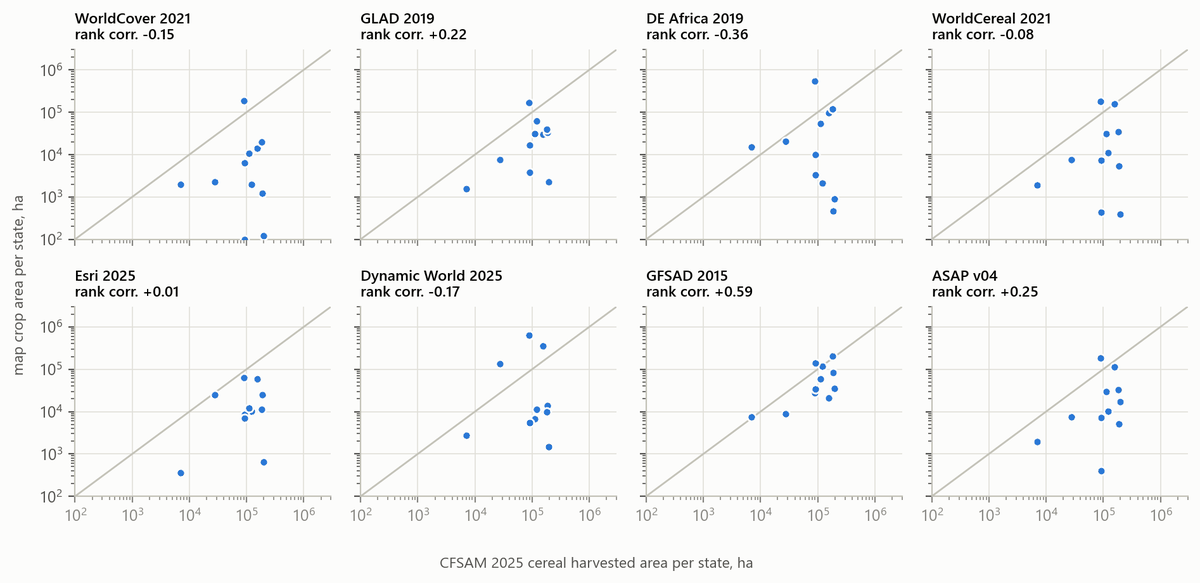

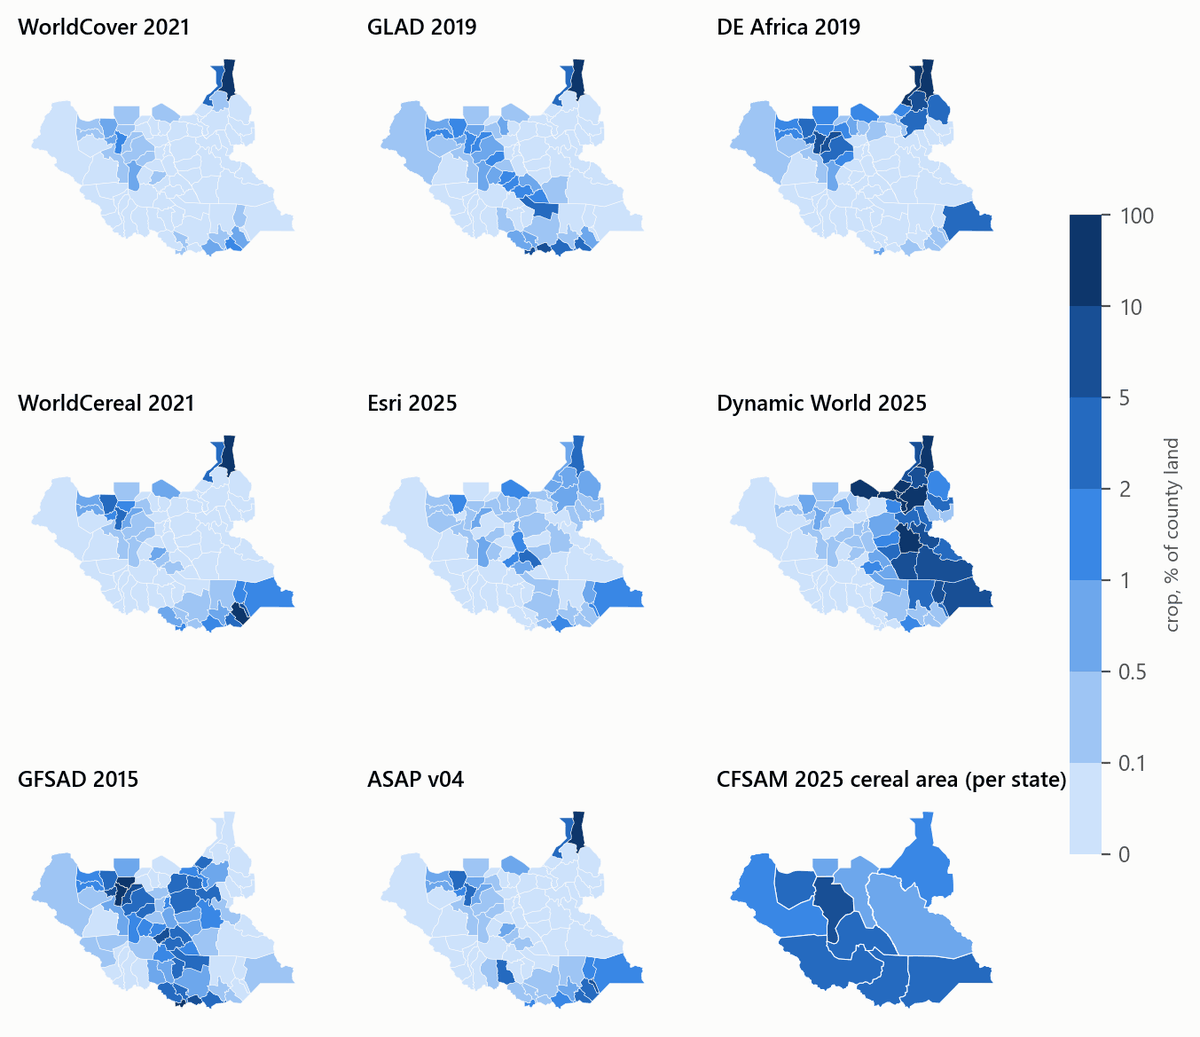

In [10]:
from scipy.stats import spearmanr
st = cty.groupby("state").sum(numeric_only=True)
cf = {y: ref[(ref.year == y) & (ref.level == "state")].groupby("state10").cereal_harvested_ha.sum() for y in (2022, 2025)}
comp = (st[maps] / 1e3).round(1).join((cf[2025] / 1e3).rename("cfsam_2025_kha")).join((cf[2022] / 1e3).rename("cfsam_2022_kha"))
comp.to_csv(D.TABLES / "state_crop_area_vs_cfsam_kha.csv")
rank = pd.DataFrame({y: {m: spearmanr(st[m], cf[y].reindex(st.index)).correlation for m in maps} for y in (2022, 2025)})
rank.to_csv(D.TABLES / "state_rank_correlation_with_cfsam.csv")
display(comp)
display(rank.round(2))
display(Image(F.states_vs_cfsam(st, cf[2025], D.MAPS + ["asap_v04"], 2025)))
display(Image(F.national_choropleths(cty, D.admin(2), D.MAPS + ["asap_v04"], cfsam_state=100 * cf[2025] / st.land_ha)))

### 1.4 Same product, different year

Esri (2017-2025) and Dynamic World (2016-2025) are remade every year from new images. Fields do move and lie fallow, but not by a factor of several from one year to the next. `still_crop_next_year_pct` is the share of one year's crop that the same product calls crop again the next year.

area    aweil       bor_south      
product    dw  esri        dw  esri
year                               
2016     1.33   NaN     13.10   NaN
2017     0.51  0.71     10.96  0.02
2018     0.80  0.61     10.54  0.01
2019     2.09  0.77      7.07  0.10
2020     0.42  0.36      0.57  0.01
2021     0.67  0.44      2.11  0.03
2022     0.79  0.42     21.33  0.06
2023     0.56  0.32      1.98  0.01
2024     0.36  0.45      5.52  0.00
2025     0.21  0.39      8.99  0.03
all      0.01  0.06      0.01  0.00
any      3.83  1.61     38.26  0.25

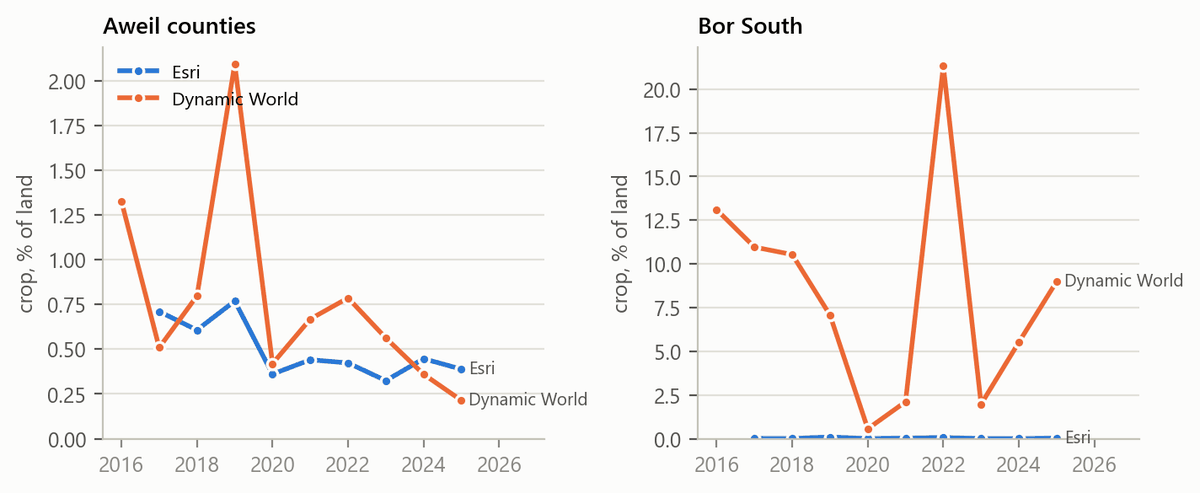

In [11]:
stab = pd.concat([D.stability(a) for a in D.C.AREAS], ignore_index=True)
if len(stab):
    stab.to_csv(D.TABLES / "same_map_every_year.csv", index=False)
    display(stab.pivot_table(index="year", columns=["area", "product"], values="crop_pct", aggfunc="first").round(2))
    display(Image(F.stability(stab)))
else:
    print("yearly exports not cached yet (stab_*.npz)")

### 1.5 Flooded cropland under each map, and a trigger

NASA MCDWD flood masks (course data, recurring + unusual), cells flooded on at least 1 (and at least 10) days between June and December, laid over each map: the Pacetti et al. (2017) overlay that a "flood inundating cropland" trigger rests on. For 2022 the yearly products are their 2022 versions. The flood masks stop at 10 N, so the national row covers the country south of 10 N. CFSAM 2022 reports 130,000 ha of cultivated land damaged by floods nationally.

unit              Aweil counties         Bor South         South Sudan (south of 10 N)         
year                        2022    2025      2022    2025                        2022     2025
map                                                                                            
asap_v04                  1104.0   110.0       0.0     0.0                      3884.0    755.0
deafrica_2019              887.0   306.0       2.0     1.0                     13993.0   2380.0
dynamicworld_2022         5805.0  1232.0     541.0  4971.0                     21342.0  23628.0
dynamicworld_2025          850.0   237.0     105.0  1600.0                     12317.0  16010.0
esri_2022                  493.0    97.0      21.0     2.0                      1825.0   1328.0
esri_2025                  331.0    10.0       1.0     0.0                      1820.0    503.0
gfsad_2015                3572.0   141.0      29.0    10.0                     21353.0   1403.0
glad_2019                  481.0    98.0      20.0     0.0                      2584.0    543.0
worldcereal_2021          1002.0    77.0       0.0     0.0                      3842.0    739.0
worldcover_2021            432.0    42.0       0.0     0.0                      1193.0    170.0

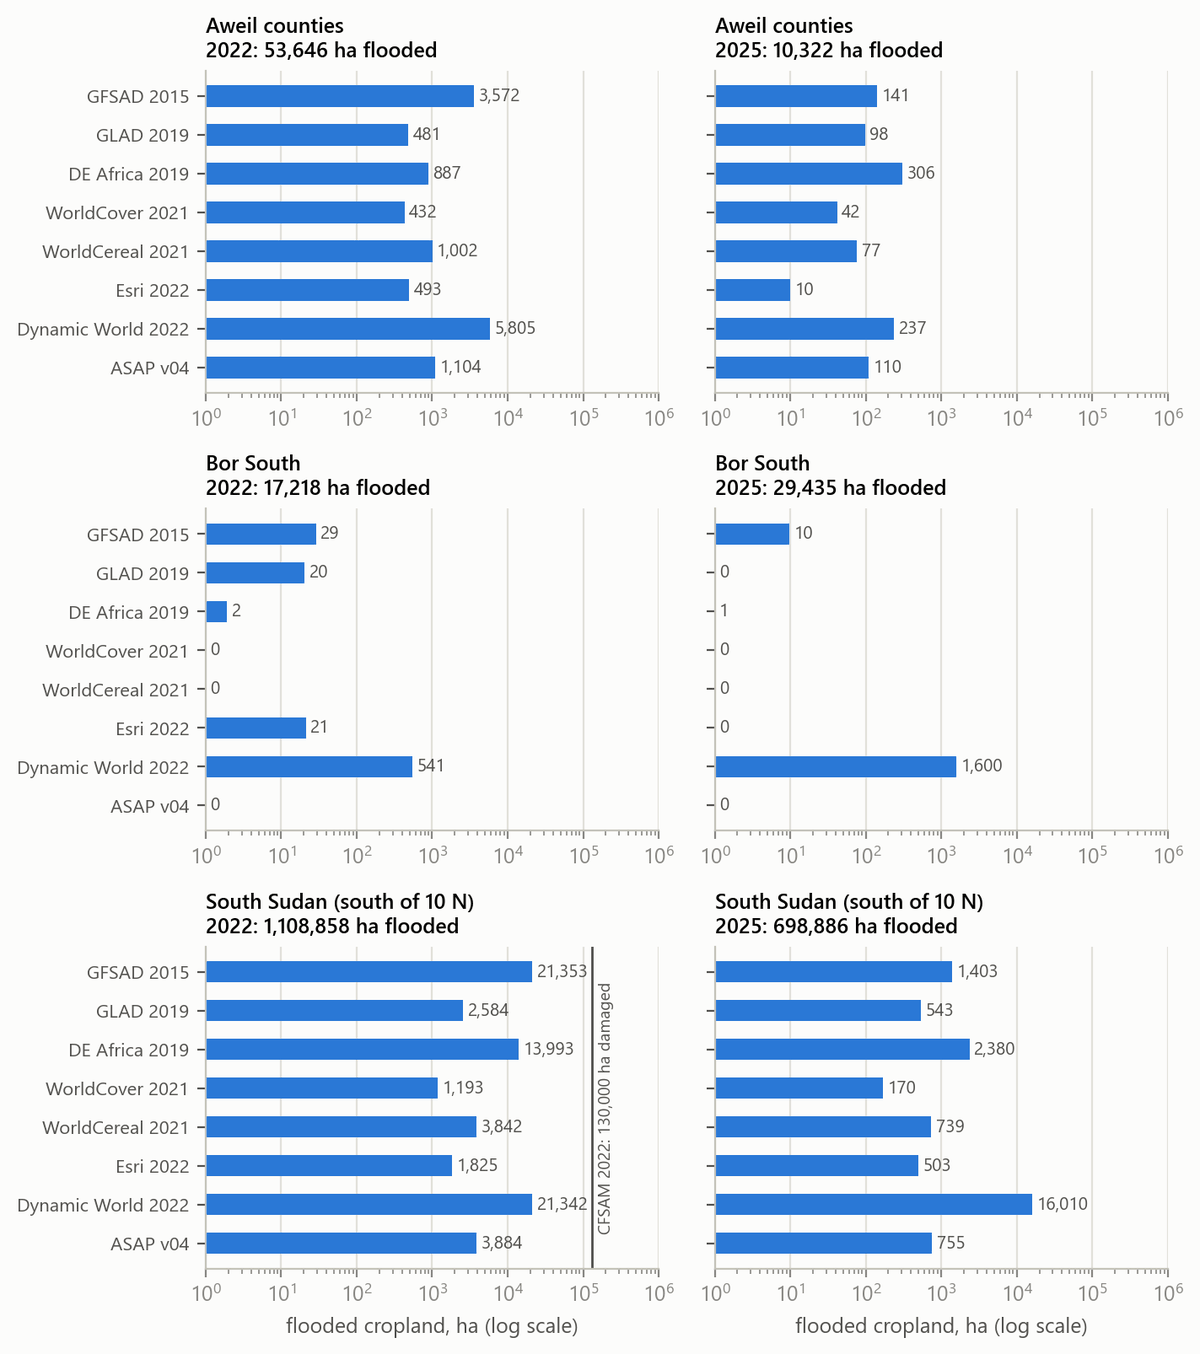

In [12]:
rows = []
for a, df in cells.items():
    for yr in (2022, 2025):
        fl = D.flood_cells(TILE[a], yr)
        for md_ in (1, 10):
            rows.append(D.flooded_crop(df, fl, min_days=md_).assign(unit=AREA_NAME[a], year=yr, min_days=md_))
if nat is not None:
    for yr in (2022, 2025):
        for md_ in (1, 10):
            rows.append(D.national_flooded_crop(nat, yr, md_).assign(unit="South Sudan (south of 10 N)", min_days=md_))
else:                                    # without national.npz: the national rows as the last full run saved them
    saved = pd.read_csv(D.TABLES / "flooded_cropland_per_map.csv", float_precision="round_trip")
    rows.append(saved[saved.unit == "South Sudan (south of 10 N)"])
flood_tab = pd.concat(rows, ignore_index=True)
flood_tab.to_csv(D.TABLES / "flooded_cropland_per_map.csv", index=False)
show = flood_tab[flood_tab.min_days == 1]
display(show.pivot_table(index="map", columns=["unit", "year"], values="flooded_crop_ha").round(0))
cf_refs = {("South Sudan (south of 10 N)", 2022): [("CFSAM 2022: 130,000 ha damaged", 130000)]}
display(Image(F.flooded(show, cf_refs)))

In [13]:
# a hard trigger on hectares (Q&A 2, slide 31): which maps would fire it?
def same_year(m, yr):
    return m.replace("_2025", f"_{yr}") if m.startswith(("esri", "dynamicworld")) else m

trig = []
for (u, yr), t in show.groupby(["unit", "year"]):
    v = t.set_index("map").flooded_crop_ha
    v = v[[same_year(m, yr) for m in D.MAPS] + ["asap_v04"]]
    for thr in (100, 500, 1000, 5000):
        fire = v[v >= thr]
        trig.append({"unit": u, "year": yr, "threshold_ha": thr, "maps_firing": len(fire), "of": len(v),
                     "which": ", ".join(D.NAMES[m] for m in fire.index),
                     "min_ha": v.min(), "max_ha": v.max()})
trig = pd.DataFrame(trig)
trig.to_csv(D.TABLES / "trigger_check.csv", index=False)
trig

,unit,year,threshold_ha,maps_firing,of,which,min_ha,max_ha
0,Aweil counties,2022,100,8,8,"WorldCover 2021, GLAD 2019, DE Africa 2019, Wo...",431.960157,5804.785384
1,Aweil counties,2022,500,5,8,"DE Africa 2019, WorldCereal 2021, Dynamic Worl...",431.960157,5804.785384
2,Aweil counties,2022,1000,4,8,"WorldCereal 2021, Dynamic World 2022, GFSAD 20...",431.960157,5804.785384
3,Aweil counties,2022,5000,1,8,Dynamic World 2022,431.960157,5804.785384
4,Aweil counties,2025,100,4,8,"DE Africa 2019, Dynamic World 2025, GFSAD 2015...",10.023263,306.228129
5,Aweil counties,2025,500,0,8,,10.023263,306.228129
6,Aweil counties,2025,1000,0,8,,10.023263,306.228129
7,Aweil counties,2025,5000,0,8,,10.023263,306.228129
8,Bor South,2022,100,1,8,Dynamic World 2022,0.000000,541.335033
9,Bor South,2022,500,1,8,Dynamic World 2022,0.000000,541.335033


### 1.6 Along the Lol

ZOA works along the Lol river (Q&A 2, slide 3). As a proxy for ZOA's communities we take land within 5 km of the Lol (OpenStreetMap line, `lol_river_osm.geojson`) inside the Aweil counties.

strip: 246,894 ha, 8.0% of the Aweil counties


,strip,rest,ratio_strip_to_rest
worldcover_2021,2.13,0.20,10.87
glad_2019,2.64,0.85,3.09
deafrica_2019,4.47,1.54,2.90
worldcereal_2021,3.27,0.80,4.08
esri_2025,0.25,0.40,0.63
dynamicworld_2025,1.07,0.14,7.53
gfsad_2015,2.44,1.87,1.30
esri_2022,0.37,0.43,0.86
dynamicworld_2022,5.09,0.42,12.09
asap_v04,3.18,0.77,4.12


year,2022,2025
map,,
asap_v04,438.0,102.0
deafrica_2019,519.0,304.0
dynamicworld_2022,3575.0,1058.0
dynamicworld_2025,586.0,224.0
esri_2022,48.0,38.0
esri_2025,31.0,7.0
gfsad_2015,736.0,91.0
glad_2019,335.0,98.0
worldcereal_2021,364.0,75.0


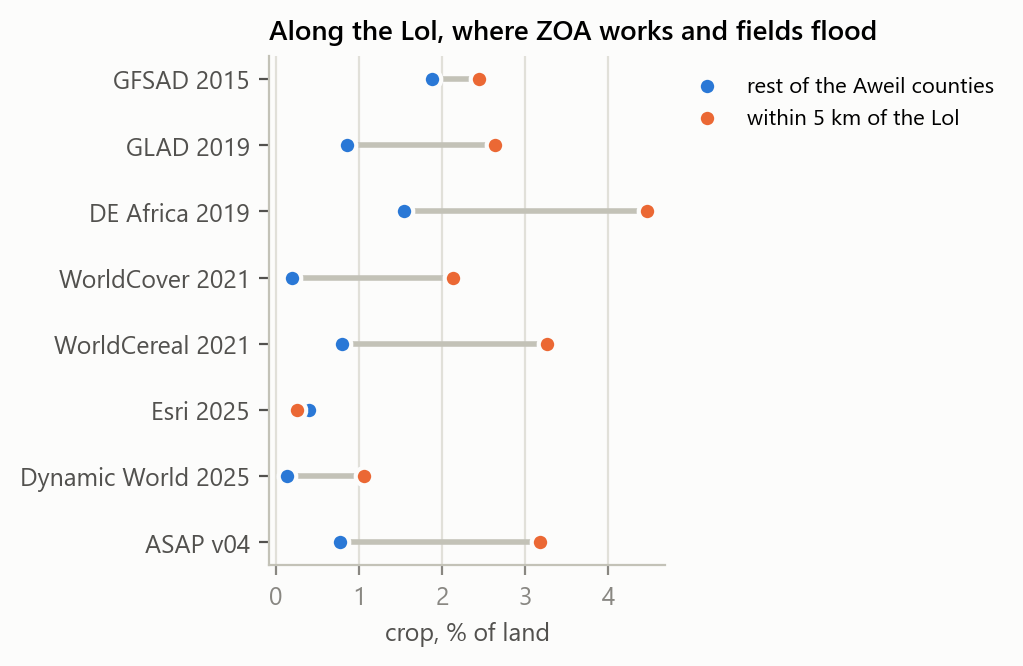

In [14]:
aw = cells["aweil"].copy()
aw["lol_km"] = D.lol_distance_km(aw)
w = aw.inside * aw.ha
strip = aw.lol_km <= 5
lol = pd.DataFrame({"strip": [100 * (aw[m] * w)[strip].sum() / w[strip].sum() for m in maps],
                    "rest": [100 * (aw[m] * w)[~strip].sum() / w[~strip].sum() for m in maps]}, index=maps)
lol["ratio_strip_to_rest"] = lol.strip / lol.rest
print(f"strip: {w[strip].sum():,.0f} ha, {100 * w[strip].sum() / w.sum():.1f}% of the Aweil counties")
fl_strip = []
for yr in (2022, 2025):
    f = D.flooded_crop(aw[strip], D.flood_cells("h20v08", yr), min_days=1)
    fl_strip.append(f.assign(year=yr))
fl_strip = pd.concat(fl_strip)
lol.to_csv(D.TABLES / "lol_strip_crop_share.csv")
fl_strip.to_csv(D.TABLES / "lol_strip_flooded_cropland.csv", index=False)
display(lol.round(2))
display(fl_strip.pivot_table(index="map", columns="year", values="flooded_crop_ha").round(0))
display(Image(F.lol_strip(lol)))

### 1.7 What the choice of map does to a damage or cash estimate (illustration)

Upper bound only: it assumes every flooded crop field is lost, which CFSAM says did not happen in 2025 (floods came late, crops were mature). The point is the spread between maps, not the level. Inputs: CFSAM net cereal yield and area per farming household of the same year (`reference_statistics.csv`), 110 kg cereal per person per year (CFSAM), and, as an assumption to check before quoting, the REACH JMMI 2025 figures: survival basket about USD 149 per 6-person household per month (August 2025), sorghum about USD 0.63 per kg (October 2025).

In [15]:
def per_area(a, yr):
    t = county[(county.year == yr) & county.name.str.startswith("Aweil" if a == "aweil" else "Bor")]
    return t.net_cereal_t.sum() / t.cereal_harvested_ha.sum(), t.cereal_harvested_ha.sum() / t.farming_households.sum()

nat_rows = ref[ref.level == "national"].set_index("year")
size = []
for (u, yr), t in show.groupby(["unit", "year"]):
    a = {"Aweil counties": "aweil", "Bor South": "bor_south"}.get(u)
    if a:
        y_net, ha_hh = per_area(a, yr)
    else:
        y_net = nat_rows.loc[yr, "net_cereal_t"] / nat_rows.loc[yr, "cereal_harvested_ha"] if yr in nat_rows.index else np.nan
        ha_hh = nat_rows.loc[yr, "ha_per_farming_household"] if yr in nat_rows.index else np.nan   # national average (2022 only)
    for m, ha in t.set_index("map").flooded_crop_ha.items():
        if m not in [same_year(x, yr) for x in D.MAPS] + ["asap_v04"]:
            continue                                       # Esri / Dynamic World: only the version of that year
        size.append({"unit": u, "year": yr, "map": m, "flooded_crop_ha": ha, "net_yield_t_ha": y_net,
                     "cereal_t": ha * y_net, "people_fed_one_year": ha * y_net / 0.110,
                     "farming_households": ha / ha_hh if ha_hh == ha_hh else np.nan,
                     "harvest_value_usd": ha * y_net * 630, "basket_usd_one_month": ha / ha_hh * 149 if ha_hh == ha_hh else np.nan})
size = pd.DataFrame(size)
size.to_csv(D.TABLES / "damage_and_cash_sizing.csv", index=False)
size.groupby(["unit", "year"]).agg(min_t=("cereal_t", "min"), max_t=("cereal_t", "max"),
                                   min_hh=("farming_households", "min"), max_hh=("farming_households", "max")).round(0)

min_t    max_t  min_hh   max_hh
unit                        year                                  
Aweil counties              2022   302.0   4060.0   568.0   7636.0
                            2025     8.0    235.0    13.0    399.0
Bor South                   2022     0.0    325.0     0.0    742.0
                            2025     0.0    896.0     0.0   2051.0
South Sudan (south of 10 N) 2022  1035.0  18529.0  1325.0  23726.0
                            2025   164.0  15427.0     NaN      NaN

### 1.8 Methodology: how well do two labellers agree?

Labels only, no features or maps, so nothing leaks into Rule 1. Each sample point is labelled by two of five people (the letters A-E), blind to each other and to every map. Kappa corrects agreement for chance (Cohen 1960), but drops to 0 when one class is rare even if people almost always agree, so we also give positive and negative specific agreement (Cicchetti and Feinstein 1990). All 450 points, labelled twice (finished 12 Oct 2026). Where the two split on cropland versus not, we also list which of their answers differed (cover class, crop cues), to see what the disagreement is about.

450 of 450 points labelled twice


,by,group,points,cropland_agree,cropland_kappa,cropland_pos_agree,cropland_neg_agree,cropland_either_says
0,all,all,450,0.856,0.704,0.839,0.903,200
1,area,aweil,330,0.833,0.679,0.862,0.862,190
2,area,bor_south,120,0.917,0.144,0.182,0.960,10
3,area x stratum,"('aweil', 'A')",150,0.913,0.576,0.645,0.958,22
4,area x stratum,"('aweil', 'B')",90,0.711,0.317,0.841,0.524,78
5,area x stratum,"('aweil', 'C')",90,0.822,-0.074,0.919,0.000,90
6,area x stratum,"('bor_south', 'A')",60,0.983,0.000,0.000,0.992,1
7,area x stratum,"('bor_south', 'B')",60,0.850,0.158,0.200,0.926,9
8,split,calibration,150,0.833,0.660,0.820,0.903,64
9,split,test,300,0.867,0.726,0.847,0.903,136


col_0,crop,fallow,not crop,unsure
row_0,,,,
crop,134,4,50,9
fallow,4,0,3,0
not crop,50,3,247,3
unsure,9,0,3,0


,points,median_min,mean_min,total_hours,conf3,overridden
labeller,,,,,,
A,180,0.98,2.24,6.71,0.77,0.00
B,180,0.52,0.91,2.73,0.68,0.07
C,180,0.58,2.43,7.28,0.42,0.04
D,180,0.68,1.10,3.31,0.78,0.03
E,180,0.68,1.83,5.48,0.64,0.01


split points                         53
different cover class                 6
cue differs: a. bare soil Apr-May    15
cue differs: b. green-up Jun-Aug     12
cue differs: c. early harvest        23
cue differs: d. field shape          41
cue differs: e. cropped in 2024      15
Name: points, dtype: int64

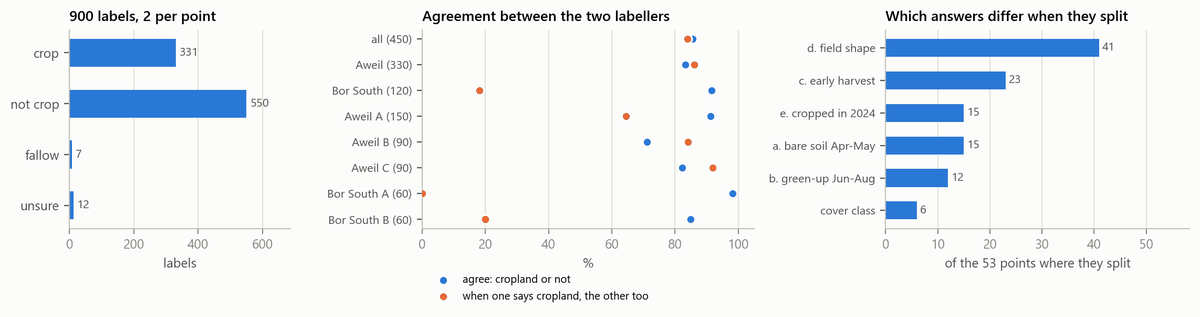

In [16]:
d = L.pairs()
d["pair"] = d.labeller_1 + " & " + d.labeller_2
lab = pd.concat([L.summary(d).assign(by="all"),
                 L.summary(d, by="area").assign(by="area"),
                 L.summary(d, by=["area", "stratum"]).assign(by="area x stratum"),
                 L.summary(d, by="split").assign(by="split"),
                 L.summary(d, by="pair").assign(by="pair")], ignore_index=True)
lab["group"] = lab.group.astype(str)
lab.to_csv(D.TABLES / "label_agreement.csv", index=False)
L.confusion(d).to_csv(D.TABLES / "label_confusion.csv")
split_points, causes = L.disagreement_causes(d)
split_points.to_csv(D.TABLES / "label_disagreement_causes_per_point.csv", index=False)
causes.to_csv(D.TABLES / "label_disagreement_causes.csv")
eff = L.effort()
eff.to_csv(D.TABLES / "label_effort.csv")
print(f"{len(d)} of 450 points labelled twice")
display(lab[["by", "group", "points", "cropland_agree", "cropland_kappa", "cropland_pos_agree", "cropland_neg_agree", "cropland_either_says"]].round(3))
display(L.confusion(d))
display(eff.round(2))
display(causes)
all_labels = pd.concat([pd.read_csv(f) for f in sorted((L.C.HERE / "labels").glob("sample_labels_*.csv"))]).label.value_counts()
groups = lab[lab.by.isin(["all", "area", "area x stratum"])].copy()
groups["group"] = groups.group.str.replace(r"[()',]", "", regex=True).str.replace("aweil", "Aweil").str.replace("bor_south", "Bor South")
display(Image(F.annotation_summary(all_labels, groups, causes)))

### 1.9 Methodology: how many points does a check need?

Neyman-optimal sample size for a target coefficient of variation (Olofsson et al. 2014; Skakun 2025; Adebayo et al. 2026, Eq. 5), with our Aweil strata weights and a range of crop shares per stratum (the real ones come from the labels). The first line checks the code against Adebayo et al. (Table 4, Kenya, GLAD: 616 points). The last column shows where the uncertainty comes from: the stratum where no map sees crop.

In [17]:
W, p = E.one_map_strata(0.09, 0.575, 0.630)
print(f"check, Kenya / GLAD: {E.n_opt(W, p, 0.10):.0f} points (paper 616)")
strata = pd.read_csv("strata_areas.csv")
Wa = strata[strata.area == "aweil"].share.to_numpy()
n_now = np.array([150, 90, 90])
grid = []
for pA in (0.01, 0.02, 0.03, 0.05):
    for pB in (0.2, 0.4):
        p = np.array([pA, pB, 0.6])
        se = E.se_share(Wa, p, n_now)
        f = (Wa * p).sum()
        grid.append({"p_A (0 maps)": pA, "p_B (1-2)": pB, "p_C (3+)": 0.6, "crop_pct": 100 * f,
                     "ci95_pp_with_150_90_90": 196 * se, "cv_pct": 100 * se / f,
                     "n_for_cv_20pct": E.n_opt(Wa, p, 0.20), "n_for_cv_10pct": E.n_opt(Wa, p, 0.10),
                     "share_of_variance_from_A": Wa[0] ** 2 * p[0] * (1 - p[0]) / (n_now[0] - 1) / se ** 2})
grid = pd.DataFrame(grid)
grid.to_csv(D.TABLES / "sample_size_planning_aweil.csv", index=False)
grid.round(2)

check, Kenya / GLAD: 591 points (paper 616)


,p_A (0 maps),p_B (1-2),p_C (3+),crop_pct,ci95_pp_with_150_90_90,cv_pct,n_for_cv_20pct,n_for_cv_10pct,share_of_variance_from_A
0,0.01,0.2,0.6,2.08,1.57,38.35,759.39,3037.56,0.94
1,0.01,0.4,0.6,3.03,1.59,26.82,387.30,1549.22,0.91
2,0.02,0.2,0.6,3.03,2.17,36.50,638.60,2554.40,0.97
3,0.02,0.4,0.6,3.98,2.19,28.07,392.69,1570.74,0.95
4,0.03,0.2,0.6,3.98,2.63,33.69,524.07,2096.27,0.98
5,0.03,0.4,0.6,4.93,2.65,27.40,358.89,1435.57,0.97
6,0.05,0.2,0.6,5.88,3.35,29.02,373.43,1493.73,0.99
7,0.05,0.4,0.6,6.83,3.36,25.10,287.89,1151.57,0.98


### 1.9b Methodology: does the 95% interval hold? (simulation)

Before the labels were in, we checked the area interval on made-up data with our exact design: Aweil and Bor South strata weights and points, a range of crop rates per stratum, and for the main measure (share of box) the share of each cropland box drawn from the five labelling classes, with smaller fields where no map sees crop. 20,000 samples per case (`evaluation.simulate_interval_coverage`).

The estimator is unbiased, but the usual ±1.96 SE interval holds the truth far less than 95% of the time, and every miss lies below the truth: when no cropland box falls in stratum A, that stratum adds nothing to the estimate or its error. The adjusted interval (`evaluation.area_interval`) keeps the estimate and the lower bound and takes the upper bound from a cautious variance (one more cropland and one more empty box per stratum, with the cropland shares of the whole area). Proposed as an addition to METHODOLOGY.md (report notes, file 06, section 6.7).

In [18]:
mix = {"A": [0.5, 0.3, 0.15, 0.05], "B": [0.25, 0.35, 0.25, 0.15], "C": [0.15, 0.3, 0.3, 0.25]}
Wb = strata[strata.area == "bor_south"].share.to_numpy()
cov = []
for measure in ("box holds cropland", "share of box"):
    for pA in (0.005, 0.01, 0.02, 0.05, 0.10):
        for pB in (0.2, 0.4):
            sm = None if measure == "box holds cropland" else [mix["A"], mix["B"], mix["C"]]
            cov.append({"area": "Aweil (150/90/90)", "measure": measure, "p_A": pA, "p_B": pB, "p_C": 0.6,
                        **V.simulate_interval_coverage(Wa, [150, 90, 90], [pA, pB, 0.6], sm)})
    for pA in (0.005, 0.01, 0.02, 0.05):
        for pB in (0.02, 0.10):
            sm = None if measure == "box holds cropland" else [mix["A"], mix["B"]]
            cov.append({"area": "Bor South (60/60)", "measure": measure, "p_A": pA, "p_B": pB, "p_C": None,
                        **V.simulate_interval_coverage(Wb, [60, 60], [pA, pB], sm)})
cov = pd.DataFrame(cov)
cov.to_csv(D.TABLES / "interval_coverage_simulation.csv", index=False)
cov.groupby(["area", "measure"])[["coverage_usual", "below_truth_usual", "coverage_adjusted", "upper_extra_pp"]].agg(["min", "max"]).round(3)

coverage_usual        below_truth_usual        coverage_adjusted      upper_extra_pp       
                                                min    max               min    max               min  max            min    max
area              measure                                                                                                       
Aweil (150/90/90) box holds cropland          0.689  0.937             0.051  0.310             0.939  1.0          0.093  0.653
                  share of box                0.785  0.893             0.103  0.214             0.994  1.0          0.408  0.773
Bor South (60/60) box holds cropland          0.467  0.885             0.112  0.533             0.949  1.0          0.718  2.229
                  share of box                0.571  0.811             0.188  0.429             0.876  1.0          0.421  1.156

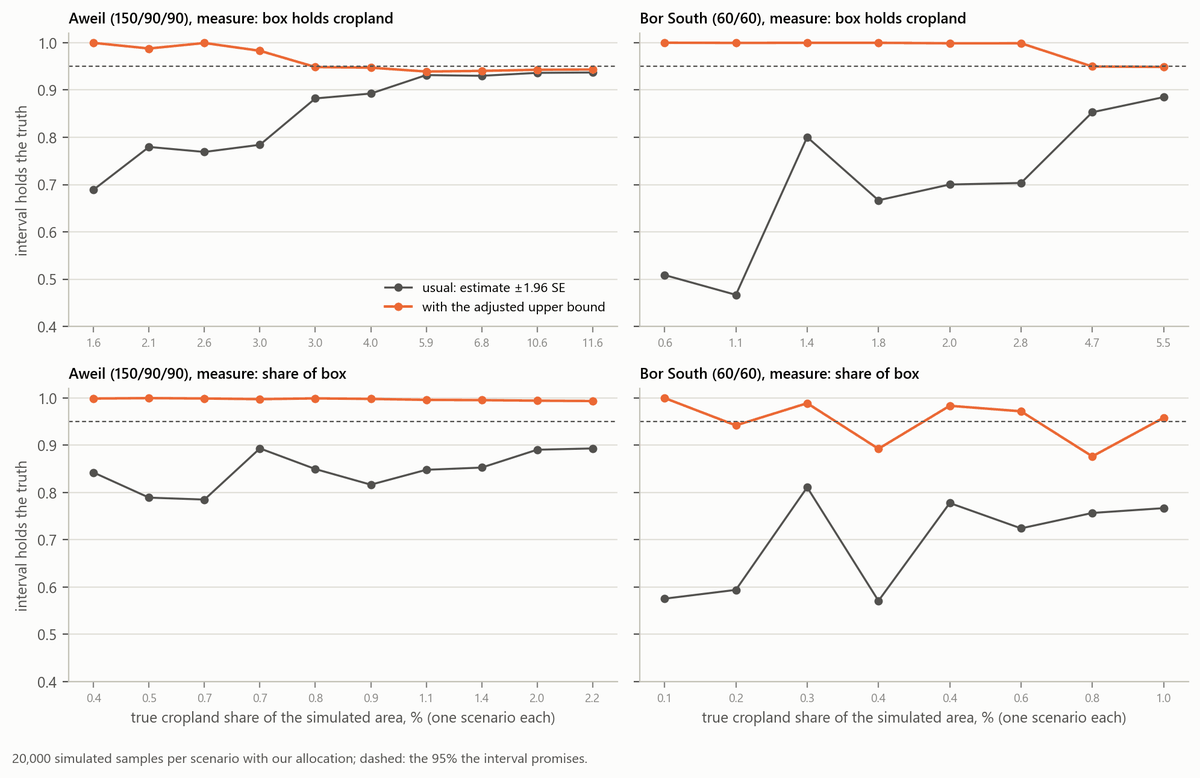

In [19]:
display(Image(RF.interval_simulation()))      # figure 25

### 1.10 Key numbers

One table of the EDA numbers the report and the poster quote (`tables/key_numbers.csv`).

In [20]:
def pct(a, m):
    return panels[AREA_NAME[a]][m]

s7 = [m for m in D.MAPS] + ["asap_v04"]
aw22 = show[(show.unit == "Aweil counties") & (show.year == 2022)].set_index("map").flooded_crop_ha
na22 = show[(show.unit == "South Sudan (south of 10 N)") & (show.year == 2022)].set_index("map").flooded_crop_ha
bs25 = show[(show.unit == "Bor South") & (show.year == 2025)].set_index("map").flooded_crop_ha
iou_off = iou_aweil.values[~np.eye(len(iou_aweil), dtype=bool)]
key = {
    "Aweil crop share, lowest map (%)": min(pct("aweil", m) for m in s7),
    "Aweil crop share, highest map (%)": max(pct("aweil", m) for m in s7),
    "Aweil CFSAM 2025 cereal area (% of land)": 100 * cfsam[("aweil", 2025)] / land_area["aweil"],
    "Aweil CFSAM 2022 cereal area (% of land)": 100 * cfsam[("aweil", 2022)] / land_area["aweil"],
    "Bor South crop share, Dynamic World 2025 (%)": pct("bor_south", "dynamicworld_2025"),
    "Bor South crop share, highest other map (%)": max(pct("bor_south", m) for m in s7 if m != "dynamicworld_2025"),
    "Aweil land no map calls crop (%)": agree_tab.loc["all counties", "0 maps"],
    "Aweil land all 7 maps call crop (%)": agree_tab.loc["all counties", "7 maps"],
    "Aweil land >= 4 maps call crop (%)": agree_tab.loc["all counties", ["4 maps", "5 maps", "6 maps", "7 maps"]].sum(),
    "Aweil pairwise IoU, best pair": np.nanmax(iou_off),
    "Aweil pairwise IoU, median pair": np.nanmedian(iou_off),
    "National crop, lowest map (Mha)": national.loc[s7, "crop_Mha"].min(),
    "National crop, highest map (Mha)": national.loc[s7, "crop_Mha"].max(),
    "National CFSAM 2025 cereal area (Mha)": refn[("CFSAM", 2025, "cereal harvested area")] / 1e6,
    "National FAOSTAT arable land (Mha)": refn[("FAOSTAT", 2022, "arable land")] / 1e6,
    "Aweil 2022 flooded cropland, lowest map (ha)": aw22[[same_year(m, 2022) for m in D.MAPS] + ["asap_v04"]].min(),
    "Aweil 2022 flooded cropland, highest map (ha)": aw22[[same_year(m, 2022) for m in D.MAPS] + ["asap_v04"]].max(),
    "National 2022 flooded cropland, lowest map (ha)": na22[[same_year(m, 2022) for m in D.MAPS] + ["asap_v04"]].min(),
    "National 2022 flooded cropland, highest map (ha)": na22[[same_year(m, 2022) for m in D.MAPS] + ["asap_v04"]].max(),
    "National 2022 flooded cropland, ASAP (ha)": na22["asap_v04"],
    "CFSAM 2022 cultivated land damaged by floods (ha)": 130000,
    "Bor South 2025 flooded cropland, Dynamic World (ha)": bs25["dynamicworld_2025"],
    "Bor South 2025 flooded cropland, all other maps (ha, max)": bs25[[m for m in s7 if m != "dynamicworld_2025"]].max(),
    "Labelled twice so far (points)": len(d),
    "Labeller splits on cropland (points)": causes["split points"],
    "Exact label agreement (%)": 100 * lab.loc[lab.by == "all", "label_agree"].iloc[0],
    "Exact label agreement (points)": round(lab.loc[lab.by == "all", "label_agree"].iloc[0] * len(d)),
    "Labels given (judgements)": int(all_labels.sum()),
    "Splits where field shape answers differ (points)": causes["cue differs: d. field shape"],
    "Labellers agree cropland vs not, Aweil (%)": 100 * lab.loc[(lab.by == "area") & (lab.group == "aweil"), "cropland_agree"].iloc[0],
    "Cohen's kappa cropland vs not, Aweil": lab.loc[(lab.by == "area") & (lab.group == "aweil"), "cropland_kappa"].iloc[0],
    "Cohen's kappa cropland vs not, Bor South": lab.loc[(lab.by == "area") & (lab.group == "bor_south"), "cropland_kappa"].iloc[0],
    "Labellers agree cropland vs not (%)": 100 * lab.loc[lab.by == "all", "cropland_agree"].iloc[0],
    "Cohen's kappa cropland vs not": lab.loc[lab.by == "all", "cropland_kappa"].iloc[0],
    "Esri F1 in Mali, Kerner et al. 2024": pub.loc["esri_2025", "kerner_f1_mali"],
    "Esri accuracy in Mali, Kerner et al. 2024": pub.loc["esri_2025", "kerner_accuracy_mali"],
    "Rank corr. published recall (Kerner) vs Aweil crop share": rho.loc["Aweil counties", "Kerner recall (7 maps)"],
    "Rank corr. published recall (Kerner) vs Bor South crop share": rho.loc["Bor South", "Kerner recall (7 maps)"],
    "Aweil land (ha)": land_area["aweil"],
    "Bor South land (ha)": land_area["bor_south"],
    "Aweil land all 7 maps call crop (ha)": agree_tab.loc["all counties", "7 maps"] / 100 * land_area["aweil"],
    "Usual interval coverage, lowest (%)": 100 * cov.coverage_usual.min(),
    "Usual interval coverage, highest (%)": 100 * cov.coverage_usual.max(),
    "Adjusted interval coverage, lowest (%)": 100 * cov.coverage_adjusted.min(),
    "Adjusted interval coverage, lowest in Aweil (%)": 100 * cov[cov.area.str.startswith("Aweil")].coverage_adjusted.min(),
}
key = pd.Series(key, name="value")
key.to_csv(D.TABLES / "key_numbers.csv")
key.round(3)

Aweil crop share, lowest map (%)                                      0.216
Aweil crop share, highest map (%)                                     1.919
Aweil CFSAM 2025 cereal area (% of land)                              3.615
Aweil CFSAM 2022 cereal area (% of land)                              5.408
Bor South crop share, Dynamic World 2025 (%)                          8.990
Bor South crop share, highest other map (%)                           0.249
Aweil land no map calls crop (%)                                     94.966
Aweil land all 7 maps call crop (%)                                   0.000
Aweil land >= 4 maps call crop (%)                                    0.065
Aweil pairwise IoU, best pair                                         0.161
Aweil pairwise IoU, median pair                                       0.042
National crop, lowest map (Mha)                                       0.223
National crop, highest map (Mha)                                      1.797
National CFS

## 2. Sample, labels and features (steps 00-06)

The method in one picture (figure 17): strata from map agreement, a random sample, two blind labels per box, Rule 1 fitted on the calibration points, every map scored on the test points, the area estimated from all points.

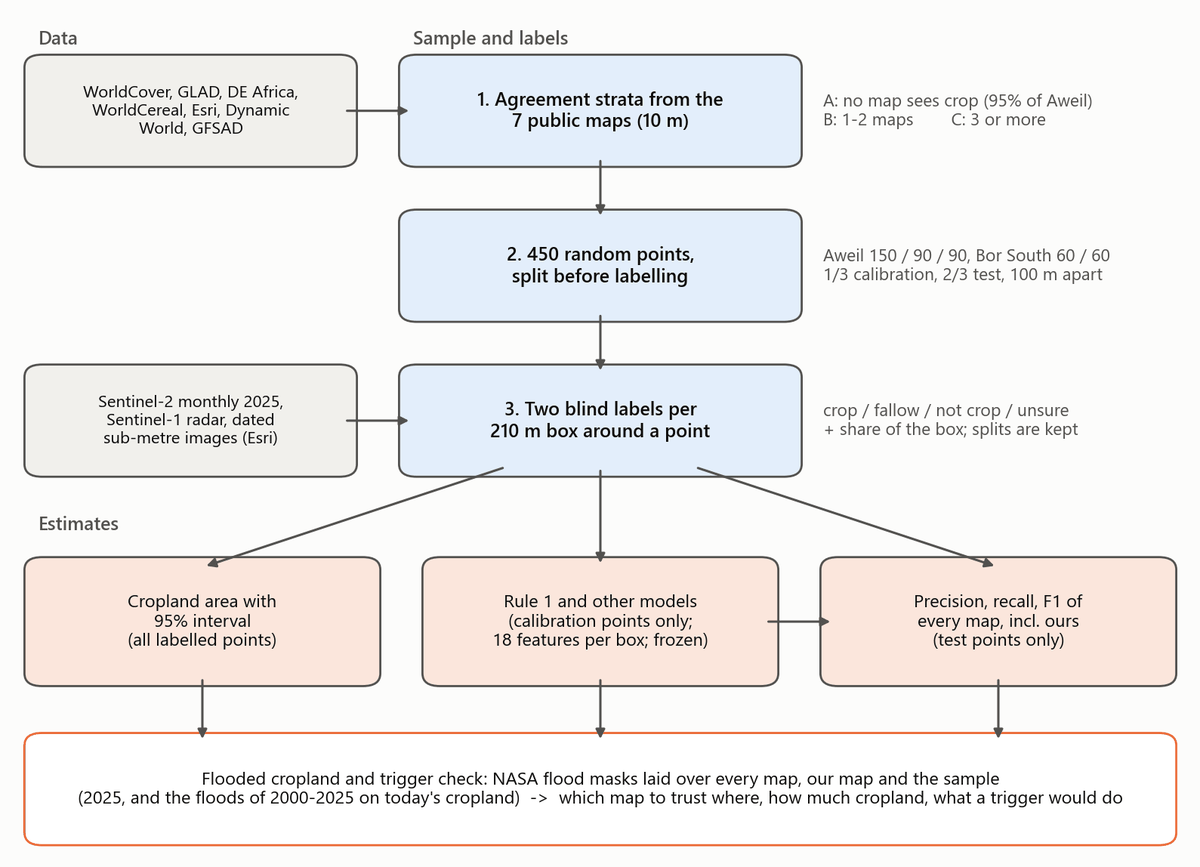

In [21]:
display(Image(RF.method_diagram()))

### 2.1 Pilot (steps 00-01)

Before the sample, five of us labelled the same 30 random points in Twic county (outside the study areas) to see whether crop can be told from grass at all. Step 00 drew the points once (seed 42, `pilot_points.csv`). Step 01 compares the labels in `labels/pilot_labels_<name>.csv`. The go rule (METHODOLOGY.md, section 4): at least 70% confident labels.

In [22]:
run("01_compare_pilot.py")

A: 30 labelled, 6 crop, 100% confident crop/not-crop, median 2.425 min/point
B: 30 labelled, 5 crop, 100% confident crop/not-crop, median 2.0500000000000003 min/point
C: 30 labelled, 6 crop, 100% confident crop/not-crop, median 1.775 min/point
D: 30 labelled, 2 crop, 87% confident crop/not-crop, median 0.9 min/point
E: 30 labelled, 0 crop, 100% confident crop/not-crop, median 0.635 min/point

A vs B: 30 points
  cropland vs not (what the estimates use): agreement 97%, kappa 0.89
  all four labels: agreement 97%, kappa 0.89
B         crop  not crop
A                       
crop         5         1
not crop     0        24

A vs C: 30 points
  cropland vs not (what the estimates use): agreement 100%, kappa 1.00
  all four labels: agreement 100%, kappa 1.00
C         crop  not crop
A                       
crop         6         0
not crop     0        24

A vs D: 30 points
  cropland vs not (what the estimates use): agreement 87%, kappa 0.55
  all four labels: agreement 87%, kappa 0.55
D

### 2.2 First look at the ASAP crop mask (step 02)

The one cropland map in the course data, ASAP v04 (about 500 m, value = percent of the cell that is crop), per county: how small the crop stratum will be.

In [23]:
run("02_strata_from_asap.py")

      county  area_ha  asap_crop_pct  cells_any_crop_pct  cells
   Bor South  1396284           0.01                 0.2  57253
Aweil Centre  1115675           0.04                 0.9  45978
  Aweil East   636753           2.99                26.4  26284
 Aweil North   634281           0.66                10.1  26201
 Aweil South   197688           1.75                22.0   8145
  Aweil West   500785           0.51                 8.3  20647
[02_strata_from_asap.py : 0 s]


### 2.3 Strata and the sample (step 03, Earth Engine, saved)

A pixel's stratum is how many of the 7 maps call it crop: A (no map), B (1-2 maps), C (3 or more). Step 03 exported this agreement map, measured the stratum areas and drew the 450 points with a fixed seed. It also split them into calibration and test points and gave each point two labellers, balanced per area, stratum and split. It ran once, before labelling: a rerun would draw a sample nobody labelled. Saved: `strata_areas.csv`, `sample.csv`.

Each point stands for its stratum's area divided by the stratum's points, so a box in Aweil's stratum A stands for far more land than one in stratum C. Every estimate below weights the points this way.

ha     share  points  ha_per_point
area      stratum                                              
aweil     A        2.929918e+06  0.949675     150       19533.0
          B        1.453270e+05  0.047105      90        1615.0
          C        9.933820e+03  0.003220      90         110.0
bor_south A        1.264445e+06  0.905579      60       21074.0
          B        1.318382e+05  0.094421      60        2197.0

split              calibration  test  All
area      stratum                        
aweil     A                 50   100  150
          B                 30    60   90
          C                 30    60   90
bor_south A                 20    40   60
          B                 20    40   60
All                        150   300  450

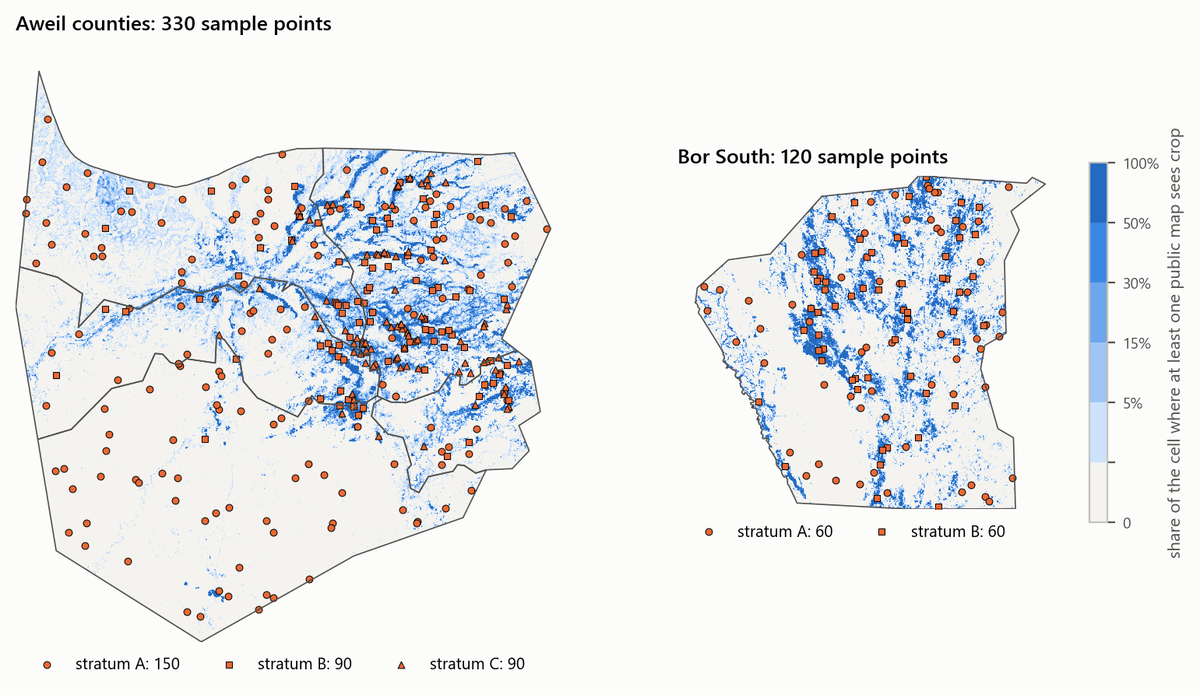

In [24]:
strata = pd.read_csv(HERE / "strata_areas.csv")
sample = pd.read_csv(HERE / "sample.csv")
points = sample.groupby(["area", "stratum"]).size().rename("points")
display(strata.set_index(["area", "stratum"]).join(points).assign(ha_per_point=lambda t: (t.ha / t.points).round(0)))
display(sample.pivot_table(index=["area", "stratum"], columns="split", values="id", aggfunc="count", margins=True))
display(Image(RF.strata_map()))               # figure 23

### 2.4 Labels (step 06)

Each point was labelled by two of five people (the letters A-E), blind to each other and to every map, with the labelling tool (`label_server.py`, `label_tool/`, guide in `LABELLING_GUIDE.md`). Step 04 made the image strips the tool shows (Earth Engine, saved as a zip, not in git). Step 06 matches the two labels per point and settles nothing: a point the two split on keeps both labels (it counts half in the area and is left out of the scores), and an "unsure" lets the other label count alone. It writes `labels_final.csv`, `labels_merged.csv`, `disagreements.csv` and `model_table.csv`, the one table every model reads. Figure 24 shows what the tool shows for one box (S017): the monthly images, the greenness of the box, its parts and the land around it, radar, and the key with both labellers' answers.

450 of 450 points labelled twice; agreement on cropland vs not: 86%; 65 disagreed, 4 crop vs fallow (disagreements.csv)
       points  disagreed  crop_vs_fallow
pair                                    
B & A      45       0.27            0.00
B & C      45       0.11            0.00
B & D      45       0.11            0.02
B & E      45       0.11            0.00
C & A      45       0.18            0.04
C & D      45       0.18            0.00
C & E      45       0.20            0.02
D & A      45       0.13            0.00
D & E      45       0.00            0.00
E & A      45       0.16            0.00
labels_final.csv: 450 points (134 crop, 0 fallow, 247 not crop, 4 crop/fallow, 0 unsure, 65 disagreed)
model_table.csv: 450 points
[06_merge_labels.py : 0 s]


final
not crop       247
crop           134
disagreed       65
crop/fallow      4
Name: points, dtype: int64

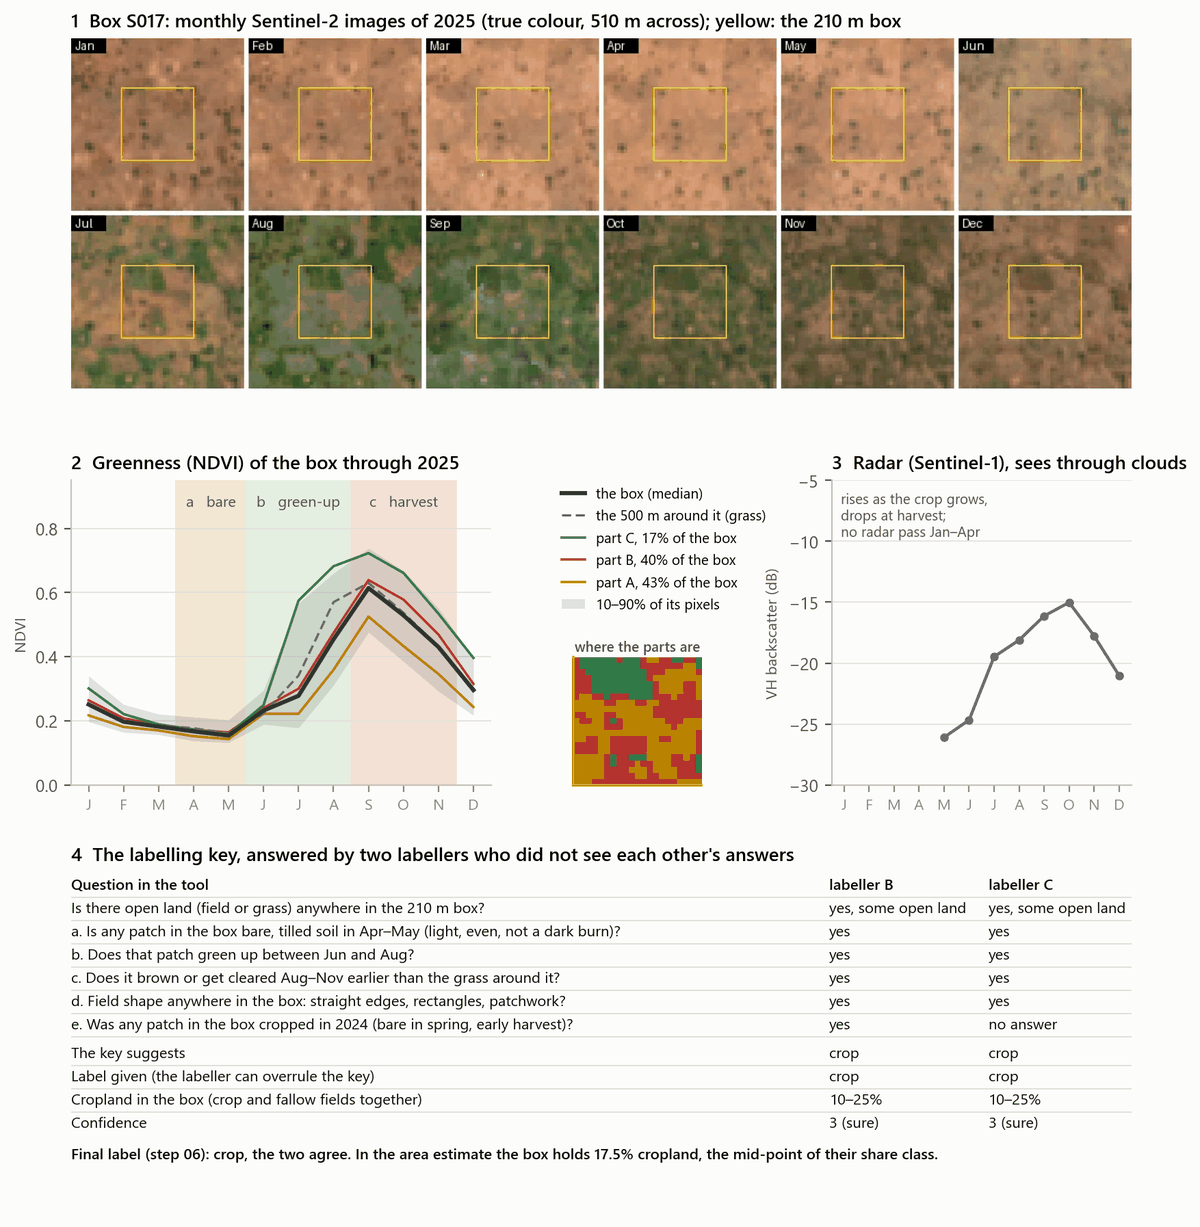

In [25]:
run("06_merge_labels.py")
lab_final = pd.read_csv(HERE / "labels_final.csv")
display(lab_final.final.value_counts().rename("points"))
if HAVE_IMAGES:
    display(Image(RF.labelling_examples()))   # figure 24
else:
    figure("24_labelling_examples")

### 2.5 Features (step 05, Earth Engine, saved)

Eighteen cues a labeller also looks at, each summarised over the point's 210 m box: greenness through the season (Sentinel-2), radar (Sentinel-1), field edges and texture, surface water, fire scars and the distance to the nearest building (`features.py`, METHODOLOGY.md section 5), plus Google's Satellite Embedding 2025 for a benchmark. Saved: `features_sample.csv`, `embedding_sample.csv`.

,count,mean,std,min,25%,50%,75%,max
ndvi_min_am,450.0,0.183,0.084,-0.146,0.132,0.158,0.210,0.741
bsi_max_am,450.0,0.242,0.050,-0.163,0.222,0.246,0.271,0.370
ndvi_peak_jja,450.0,0.717,0.099,-0.016,0.667,0.732,0.789,0.927
greenup,450.0,0.585,0.125,0.009,0.514,0.617,0.670,0.808
drop_son,450.0,0.388,0.157,-0.177,0.260,0.418,0.520,0.698
drop_vs_500m,450.0,0.106,0.065,0.001,0.053,0.100,0.150,0.424
texture_jja,450.0,120.651,129.599,2.104,13.189,61.550,207.070,635.812
edge_density,450.0,0.126,0.088,0.000,0.047,0.108,0.196,0.423
ndvi_min_jfm,450.0,0.193,0.076,-0.083,0.166,0.194,0.226,0.703
water_occurrence,450.0,0.183,3.247,0.000,0.000,0.000,0.000,68.503


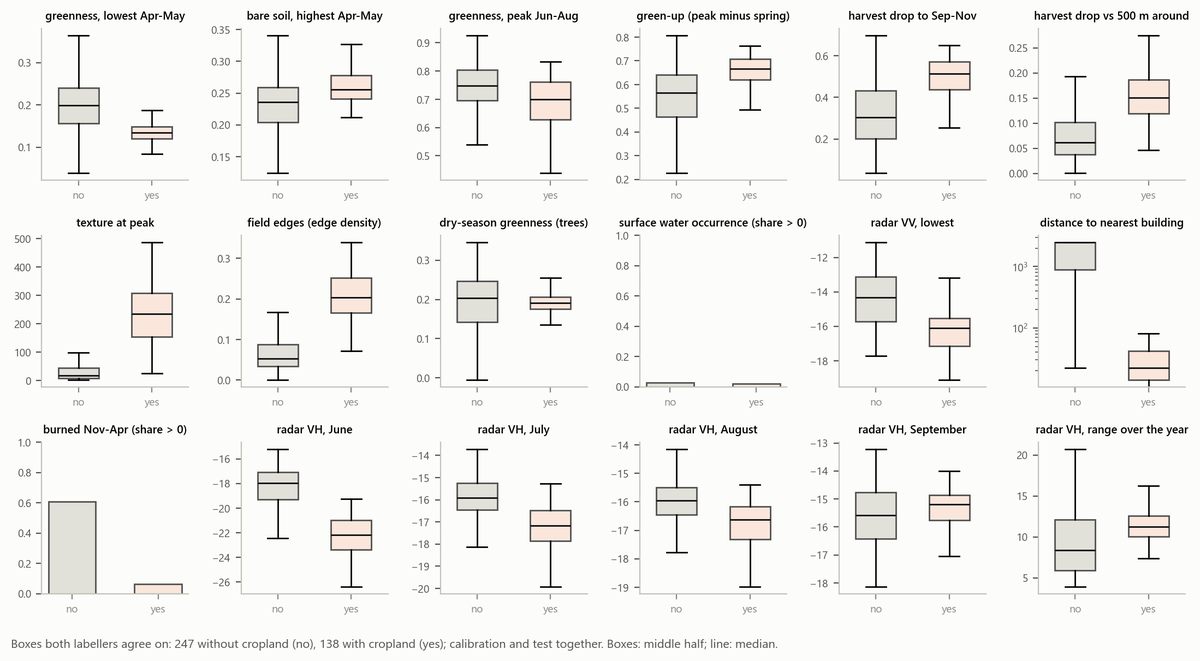

In [26]:
import features
feats = pd.read_csv(HERE / "features_sample.csv")
display(feats[features.FEATURES].describe().T.round(3))
display(Image(RF.feature_distributions()))   # figure 22

## 3. Models (steps 07, 12 and 08)

### 3.1 Rule 1 (step 07)

A decision tree on the calibration points only, target "cropped in 2025" where both labellers agree, depth 2, 3 or 4 picked by 5-fold cross-validation (the smallest depth within 0.02 F1 of the best). Rule 1 was frozen in `rule1_2026-10-12.json` before any test label was read. Here the tree is fitted again from the same points and compared with the frozen file. Nothing is saved: step 07 itself would write a new dated rule file and new benchmark forests.

cross-validated F1 by depth: {2: np.float64(0.862), 3: np.float64(0.862), 4: np.float64(0.862)} -> depth 2
125 calibration points, 41 crop
refitted:
crop if dist_buildings_m <= 333.4111 and edge_density > 0.0937
otherwise not crop
frozen on 2026-10-12:
crop if dist_buildings_m <= 333.4111 and edge_density > 0.0937
otherwise not crop


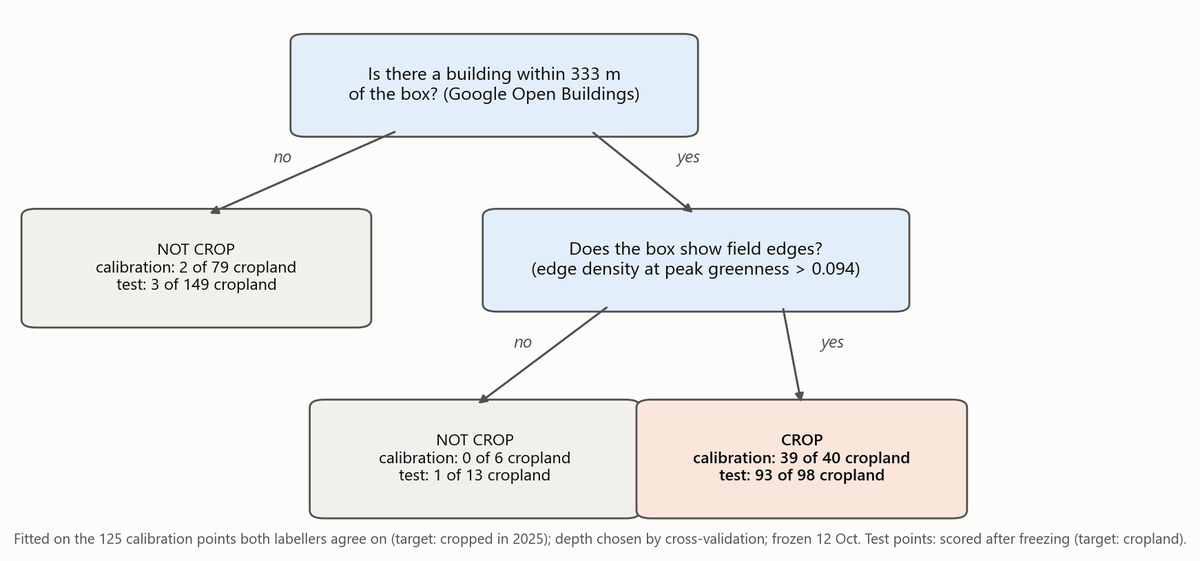

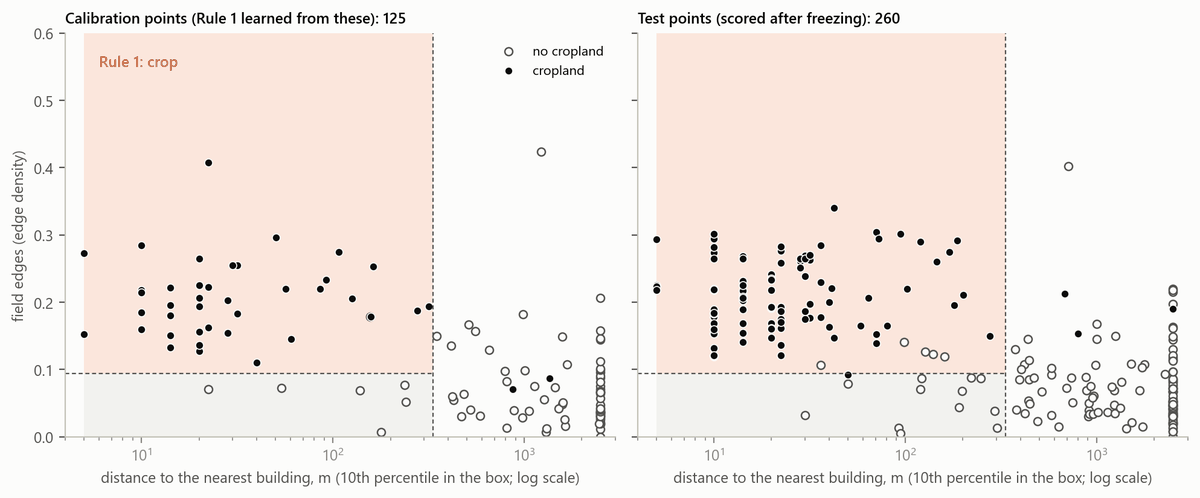

In [27]:
import importlib
import model_data as M
import rules as R

step07 = importlib.import_module("07_fit_rules")
X, y, info = M.load("calibration", target="crop")
fill = M.fill_values(X)
refit = step07.fit_tree(X.fillna(fill).to_numpy(), y, fill)
frozen = R.load(RULE1)
print(f"{len(y)} calibration points, {y.sum()} crop")
print("refitted:", R.as_text(refit), sep="\n")
print(f"frozen on {frozen['frozen']}:", R.as_text(frozen), sep="\n")
assert R.as_text(refit) == R.as_text(frozen), "the refitted tree differs from the frozen Rule 1"
display(Image(RF.rule1_tree()))     # figure 18
display(Image(RF.rule1_space()))    # figure 19

### 3.2 Other models (step 12)

Logistic regressions and other trees on the same points, inputs and target, compared by repeated cross-validation on the calibration points (no test label read). `12_other_models.py freeze <name>` fitted the two chosen logistic models on all calibration points and wrote their predictions (`results/predictions_logistic_*.csv`) and rule files (`logistic_*_2026-10-12.json`). Step 09 scores them next to Rule 1. The random forests are benchmarks only (`raw_data/cropland/benchmarks.joblib`, from step 07).

tree_d1                  F1 0.856
tree_d2                  F1 0.851


tree_d3                  F1 0.847
tree_d4                  F1 0.847


logistic_l2              F1 0.878


logistic_l1              F1 0.873


logistic_rule1_inputs    F1 0.870


rf_features              F1 0.919
                model  points  crop_points  inputs    f1  f1_low  f1_high  precision  recall  f1_weighted  beats_tree_d2_in_repeats
              tree_d1     125           41      18 0.856   0.814    0.877      0.820   0.899        0.373                      0.60
              tree_d2     125           41      18 0.851   0.804    0.900      0.823   0.883        0.393                      0.00
              tree_d3     125           41      18 0.847   0.804    0.882      0.818   0.882        0.385                      0.05
              tree_d4     125           41      18 0.847   0.804    0.882      0.818   0.882        0.385                      0.05
          logistic_l2     125           41      18 0.878   0.849    0.910      0.833   0.929        0.446                      0.80
          logistic_l1     125           41      18 0.873   0.827    0.916      0.848   0.901        0.440                      0.65
logistic_rule1_inputs     125           41

      model          feature  coef_per_sd  odds_ratio_per_sd      C
logistic_l1      ndvi_min_am      -13.860              0.000 166.81
logistic_l1       bsi_max_am        2.757             15.749 166.81
logistic_l1    ndvi_peak_jja       12.700         327601.918 166.81
logistic_l1          greenup      -27.552              0.000 166.81
logistic_l1         drop_son       11.930         151765.675 166.81
logistic_l1     drop_vs_500m        5.914            370.223 166.81
logistic_l1      texture_jja       14.457        1899682.950 166.81
logistic_l1     edge_density       -8.547              0.000 166.81
logistic_l1     ndvi_min_jfm        2.560             12.941 166.81
logistic_l1 water_occurrence        0.000              1.000 166.81
logistic_l1        s1_vv_min      -10.992              0.000 166.81
logistic_l1 dist_buildings_m      -24.540              0.000 166.81
logistic_l1           burned       10.554          38325.975 166.81
logistic_l1           vh_jun      -18.370       

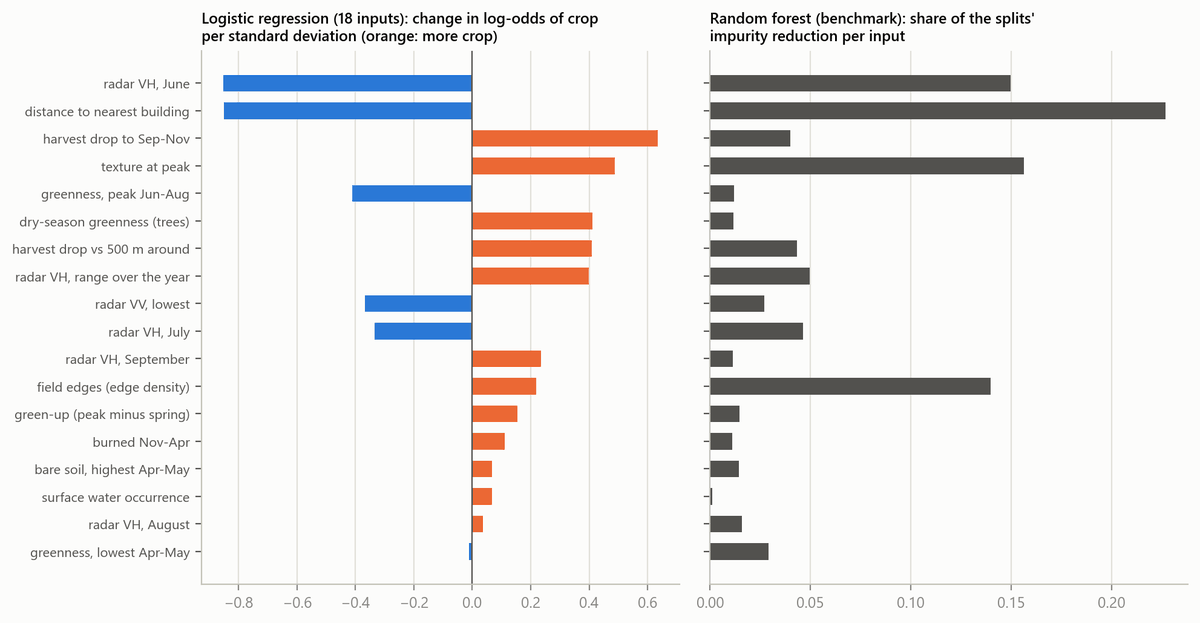

In [28]:
from sklearn.exceptions import ConvergenceWarning
with warnings.catch_warnings():
    warnings.simplefilter("ignore", ConvergenceWarning)    # liblinear stops early at the weakest penalties (large C)
    run("12_other_models.py", "compare")
display(Image(RF.what_models_learned()))      # figure 21

### 3.3 Our map (step 08, Earth Engine, saved)

`08_run_map.py` first checks that Earth Engine applies Rule 1 exactly as Python does at the calibration points (`test_cropland.py --ee` checks it too). It then exports our map: 10 m over the two study areas, 30 m over the whole country. A pixel of our map means "the 210 m box around it holds a cropped field". The map lives in Earth Engine; part 7 summarises it over the country.

## 4. The cropland area and every map's score (step 09)

Step 09 reads every map at the 450 points: the 7 public maps (Earth Engine), ASAP (course file), Rule 1 (from the frozen file), the two random-forest benchmarks and the frozen logistic models. Then:
- **area**, from all labelled points, weighted by stratum (Stehman 2014; Olofsson et al. 2014), two ways: the share of each box that is cropland (main), and whether the box holds any cropland (upper bound);
- **scores** on the test points only, where both labellers agree: precision (user's accuracy), recall (producer's accuracy) and F1 with standard errors, per area and for two definitions (cropland = crop + fallow; cropped in 2025).

Without Earth Engine (`--cached`) the public maps' values at the points come from `results/map_values.csv`, as Earth Engine gave them on 12-14 Oct 2026. Everything else is recomputed.

In [29]:
if RUN_EARTH_ENGINE:
    run("09_score.py", RULE1)
else:
    run("09_score.py", "--cached", RULE1)

     area   definition                    measure  points  left_out  share  ci_low  ci_high          ha   ci_low_ha  ci_high_ha  no_share_left_out  points_split  share_if_split_all_yes  share_if_split_all_no
    aweil     cropland               share of box     330         0 0.0378  0.0248   0.0507 116542.5084  76653.6920 156431.3249                0.0           NaN                     NaN                    NaN
    aweil     cropland box holds it (upper bound)     330         0 0.1430  0.0999   0.1862 441309.9978 308162.6921 574457.3035                NaN          44.0                  0.1833                 0.1028
    aweil cropped_2025               share of box     330         0 0.0372  0.0242   0.0501 114641.0506  74810.4604 154471.6408                0.0           NaN                     NaN                    NaN
    aweil cropped_2025 box holds it (upper bound)     330         0 0.1396  0.0967   0.1825 430570.6682 298210.4590 562930.8775                NaN          47.0        

,area,definition,measure,points,share,ci_low,ci_high,ha,ci_low_ha,ci_high_ha
0,aweil,cropland,share of box,330,0.0378,0.0248,0.0507,116542.5084,76653.6920,156431.3249
1,aweil,cropland,box holds it (upper bound),330,0.1430,0.0999,0.1862,441309.9978,308162.6921,574457.3035
2,aweil,cropped_2025,share of box,330,0.0372,0.0242,0.0501,114641.0506,74810.4604,154471.6408
3,aweil,cropped_2025,box holds it (upper bound),330,0.1396,0.0967,0.1825,430570.6682,298210.4590,562930.8775
4,bor_south,cropland,share of box,120,0.0038,0.0007,0.0070,5359.6678,997.9596,9721.3760
5,bor_south,cropland,box holds it (upper bound),120,0.0154,0.0000,0.0310,21523.5598,0.0000,43323.9576
6,bor_south,cropped_2025,share of box,120,0.0034,0.0003,0.0065,4755.4094,457.7551,9053.0638
7,bor_south,cropped_2025,box holds it (upper bound),120,0.0138,0.0000,0.0293,19326.2565,0.0000,40974.7112


,map,year,test_points,precision,recall,f1,f1_se
0,rf_features,2025 (benchmark),186,0.881,0.671,0.762,0.092
1,rule1,2025 (ours),186,0.697,0.753,0.724,0.090
2,rf_embedding,2025 (benchmark),186,0.770,0.663,0.713,0.092
3,logistic_l2,2025 (model),186,0.544,0.835,0.659,0.087
4,logistic_rule1_inputs,2025 (model),186,0.479,0.836,0.609,0.089
5,worldcereal_2021,2021,186,0.834,0.412,0.551,0.105
6,deafrica_2019,2019,186,0.398,0.662,0.497,0.085
7,asap_v04,2017-23,186,1.000,0.276,0.433,0.108
8,glad_2019,2019,186,1.000,0.259,0.411,0.105
9,worldcover_2021,2021,186,1.000,0.217,0.356,0.106


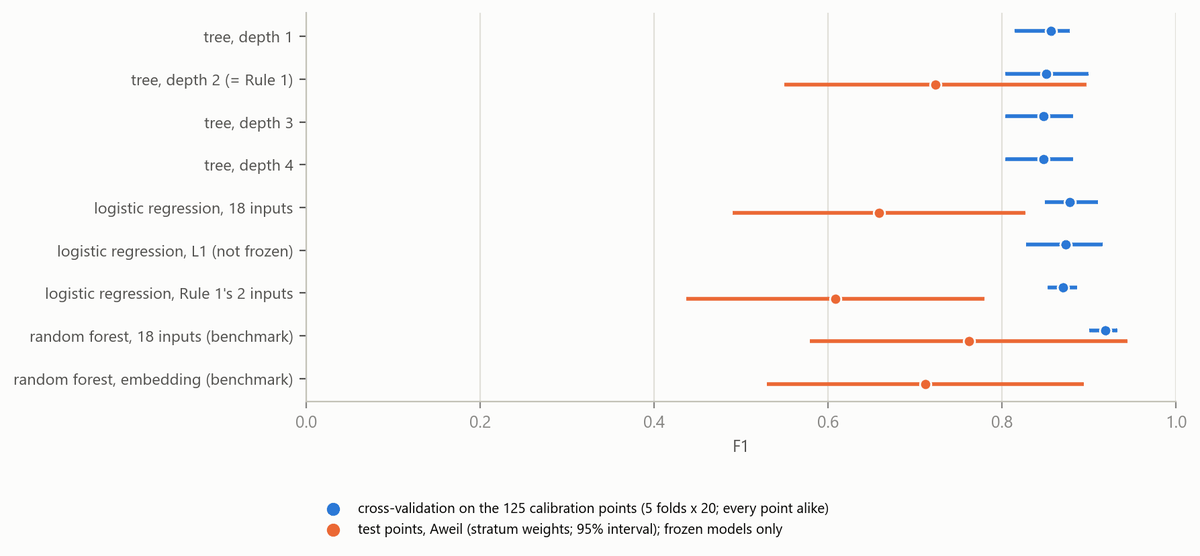

In [30]:
area = pd.read_csv(RES / "area.csv")
display(area[["area", "definition", "measure", "points", "share", "ci_low", "ci_high", "ha", "ci_low_ha", "ci_high_ha"]].round(4))
acc = pd.read_csv(RES / "accuracy.csv")
acc_aw = acc[(acc.area == "aweil") & (acc.definition == "cropland")].sort_values("f1", ascending=False)
display(acc_aw[["map", "year", "test_points", "ua", "pa", "f1", "f1_se"]]
        .rename(columns={"ua": "precision", "pa": "recall"}).round(3).reset_index(drop=True))
display(Image(RF.models_cv_vs_test()))        # figure 20: cross-validation against the test score

## 5. Floods and the trigger (steps 10, 10b, 10c)

### 5.1 Flooded cropland in 2025 (step 10, Earth Engine, saved)

The NASA flood cells of 2025 (course data) laid over every public map, ASAP and our map, with the sample's own estimate next to them. Few sample points fall in the 2025 flood cells, so the sample alone cannot measure flooded cropland in one year: hence the past floods in 5.2.

In [31]:
if RUN_EARTH_ENGINE:
    run("10_flood.py", RULE1)          # needs our map in your Earth Engine project: run 08_run_map.py first
flooded = pd.read_csv(RES / "flooded_cropland.csv")
flooded.pivot_table(index="map", columns="area", values="flooded_crop_ha", sort=False).round(0)

area,aweil,bor_south
map,,
worldcover_2021,41.0,0.0
glad_2019,97.0,0.0
deafrica_2019,307.0,1.0
worldcereal_2021,77.0,0.0
esri_2025,10.0,0.0
dynamicworld_2025,237.0,1606.0
gfsad_2015,140.0,10.0
rule1,3588.0,126.0
asap_v04,77.0,0.0


### 5.2 Past floods on today's cropland, 2000-2025 (step 10b)

A scenario, not history: how much of today's cropland would each past flood put under water? Rule 1's share in every flood cell was computed once in Earth Engine (`10b_flood_history.py model`, saved in `raw_data/cropland/`); the rest is local. The sample's estimate (ratio estimator) is given only with at least 5 sample points on flooded land. The hindcast asks, year by year, whether each map would have fired a trigger of 100 to 5,000 ha.

figure: deliverables\cropland_report\figures\12_flood_history.png
layer  asap_v04  deafrica_2019  dynamicworld_2022  dynamicworld_2025  esri_2022  esri_2025  gfsad_2015  glad_2019    rule1  sample (ratio)  worldcereal_2021  worldcover_2021
year                                                                                                                                                                         
2000        0.0            0.0               37.0                2.0       28.0        2.0         0.0        0.0     25.0             NaN               0.0              0.0
2001       19.0           11.0             1711.0               42.0       16.0       13.0        91.0        0.0    439.0             NaN               8.0              6.0
2002        0.0            1.0               40.0                6.0       11.0        0.0         0.0        0.0      2.0             NaN               0.0              0.0
2003       74.0           69.0             4964.0              2

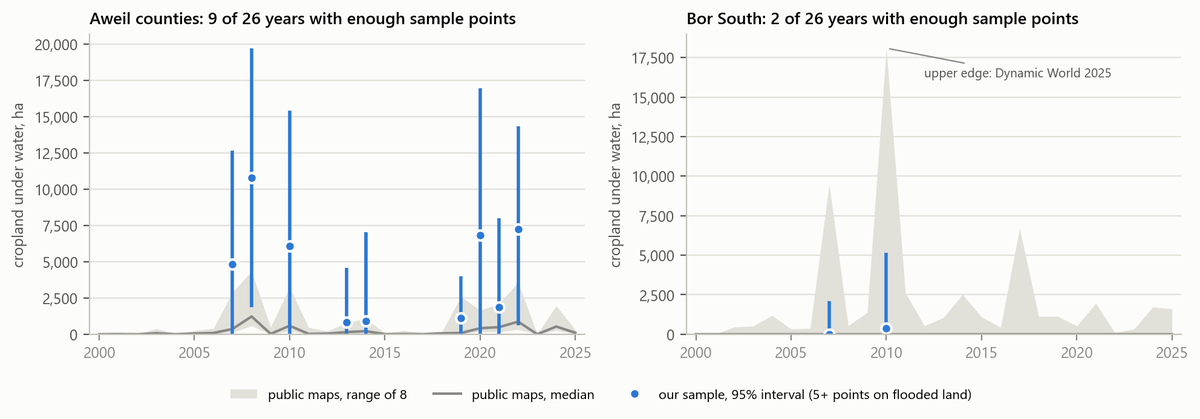

In [32]:
run("10b_flood_history.py", "summary")
figure("12_flood_history")

### 5.3 The 2022 flood in Aweil, before and after (step 10c)

The flooded cells of 2022 coloured by what the best public map (WorldCereal) and our map call crop (figure 13). The same view as an interactive map, where the "before" map can be changed: `deliverables/cropland_report/maps/flood_aweil_2022.html`.

           before  flooded_cells  shown_before  added_by_our_map  shown_only_by_public_map  no_crop_in_either  public_map_crop_ha  flooded_land_in_added_cells_ha
  worldcover_2021          10184          1439              3858                        81               4887               432.0                         20329.0
        glad_2019          10184           716              4526                        26               4942               481.0                         23858.0
    deafrica_2019          10184          3226              2474                       484               4484               887.0                         13037.0
 worldcereal_2021          10184          1646              3627                        57               4911              1002.0                         19121.0
        esri_2025          10184           150              5191                       125               4843               331.0                         27354.0
dynamicworld_2025          1

figure: deliverables\cropland_report\figures\13_flood_map_aweil_2022.png
map: deliverables\cropland_report\maps\flood_aweil_2022.html
[10c_flood_map.py aweil 2022 rule1 1: 3 s]


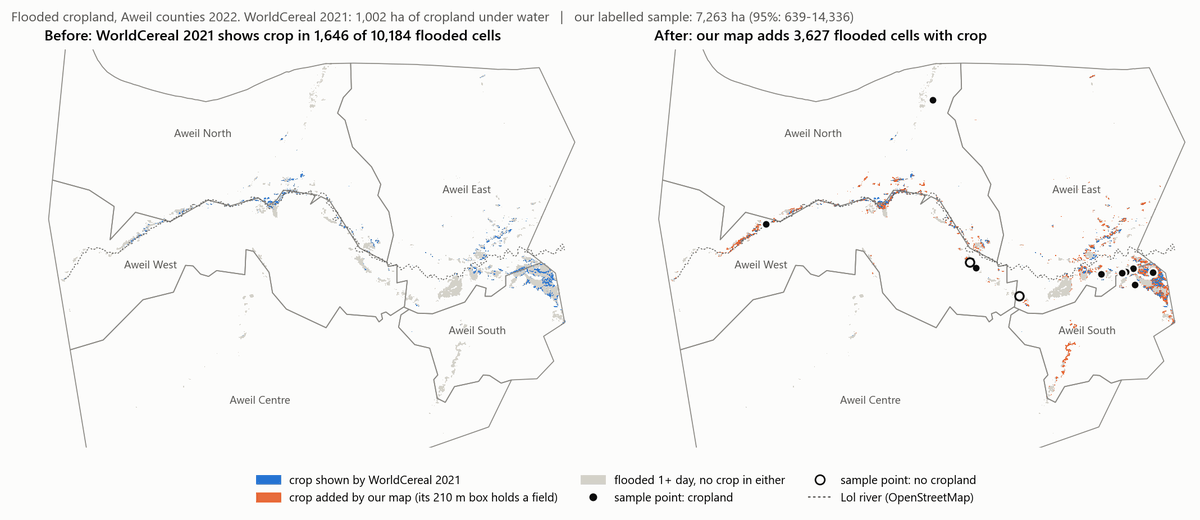

In [33]:
run("10c_flood_map.py", "aweil", 2022, "rule1", 1)
figure("13_flood_map_aweil_2022")

### 5.4 Exposure before and after our check

The report's exposure table, from 5.2: flooded cropland on today's cropland under the 8 public layers (before) and from the labelled sample (after: the ratio estimator with its 95% interval, judged only with 5 or more sample points on flooded land). Then the same hectares as farming households (cereal hectares per farming household in CFSAM 2025: illustrative, every flooded field counted as lost), and how many maps would fire a 500 ha trigger (`key_results.exposure`).

In [34]:
import key_results as K
exposure = K.exposure()
exposure.round(0).assign(ha_per_household=exposure.ha_per_household.round(2))

,area,year,flooded_land_ha,maps_min_ha,maps_max_ha,sample_points_on_flooded_land,sample_ha,sample_low_ha,sample_high_ha,ha_per_household,households_maps_min,households_maps_max,households_sample,maps_firing_500_ha,maps_scored,sample_says
0,aweil,2008,83017.0,585.0,4335.0,17,10795.0,1862.0,19729.0,0.77,764.0,5653.0,14079.0,8,8,fire
1,aweil,2022,53646.0,331.0,3572.0,11,7263.0,639.0,14336.0,0.77,432.0,4658.0,9472.0,5,8,fire
2,aweil,2025,10322.0,10.0,306.0,1,NaN,NaN,NaN,0.77,13.0,399.0,NaN,0,8,cannot tell
3,bor_south,2007,35057.0,0.0,9479.0,5,0.0,0.0,2096.0,0.78,0.0,12152.0,0.0,1,8,cannot tell
4,bor_south,2025,29435.0,0.0,1600.0,2,NaN,NaN,NaN,0.78,0.0,2051.0,NaN,1,8,cannot tell


## 6. Evaluation additions and robustness checks

### 6.1 Evaluation additions (step 11)

The adjusted area interval (a cautious upper bound for strata with no cropland box), where the maps fail, our scores against the published ones, the points a yearly check needs per sampling design, how readable each rule is, the bias of counting map pixels, and whether each map agrees with the sample on firing a trigger. Figures 14 (area against the maps) and 15 (the scorecard).

     area   definition                    measure  points  estimate    low   high  high_adjusted          ha
    aweil     cropland               share of box     330    0.0378 0.0248 0.0507         0.0593 116542.5084
    aweil     cropland box holds it (upper bound)     330    0.1430 0.0999 0.1862         0.1929 441309.9978
    aweil cropped_2025               share of box     330    0.0372 0.0242 0.0501         0.0583 114641.0506
    aweil cropped_2025 box holds it (upper bound)     330    0.1396 0.0967 0.1825         0.1882 430570.6682
bor_south     cropland               share of box     120    0.0038 0.0007 0.0070         0.0118   5359.6678
bor_south     cropland box holds it (upper bound)     120    0.0154 0.0000 0.0310         0.0391  21523.5598
bor_south cropped_2025               share of box     120    0.0034 0.0003 0.0065         0.0117   4755.4094
bor_south cropped_2025 box holds it (upper bound)     120    0.0138 0.0000 0.0293         0.0381  19326.2565


figures: deliverables\cropland_report\figures\14_area_vs_maps.png deliverables\cropland_report\figures\15_scorecard.png


     area                                                 map  points_in_flood_cells  of_them_cropland  estimate_ha  high_usual_ha  high_adjusted_ha  flooded_land_ha
    aweil                  reference: cropland (share of box)                      1                 1        606.0         1792.0           14915.0          10314.0
    aweil     reference: cropland, upper bound (box holds it)                      1                 1       1615.0         4780.0           39774.0          10314.0
    aweil              reference: cropped 2025 (share of box)                      1                 1        606.0         1792.0           14915.0          10314.0
    aweil reference: cropped 2025, upper bound (box holds it)                      1                 1       1615.0         4780.0           39774.0          10314.0
bor_south                  reference: cropland (share of box)                      2                 0          0.0            0.0           40523.0          29419.0
bor_

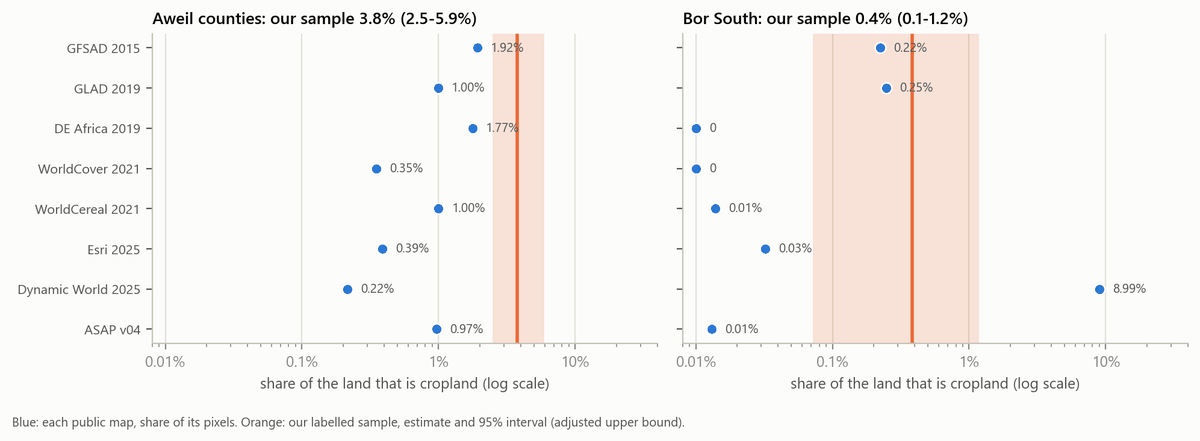

,design,n_opt,map_crop_share,crop_rate_map_crop,crop_rate_map_not_crop,relative_efficiency_of_ours,area
0,agreement strata (ours),123.7,NaN,NaN,NaN,1.0,aweil
1,worldcover_2021,126.6,0.0,0.9,0.1,1.0,aweil
2,glad_2019,131.9,0.0,0.7,0.1,1.1,aweil
3,deafrica_2019,116.9,0.2,0.4,0.1,0.9,aweil
4,worldcereal_2021,112.3,0.1,0.7,0.1,0.9,aweil
5,esri_2025,147.3,0.0,0.8,0.1,1.2,aweil
6,dynamicworld_2025,149.0,0.0,0.3,0.1,1.2,aweil
7,gfsad_2015,136.6,0.0,0.6,0.1,1.1,aweil
8,asap_v04,121.6,0.0,0.8,0.1,1.0,aweil
9,agreement strata (ours),1236.7,NaN,NaN,NaN,1.0,bor_south


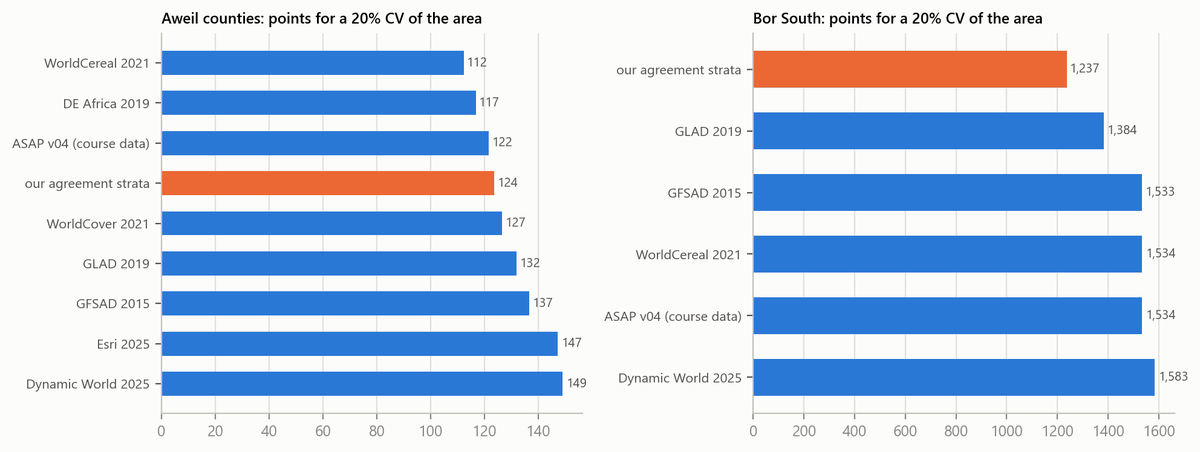

In [35]:
run("11_evaluate.py", RULE1)
figure("14_area_vs_maps")
display(pd.read_csv(RES / "design_efficiency.csv").round(1))
display(Image(RF.design_points()))            # figure 26

### 6.2 Robustness checks (`sensitivity.py`)

Checks run after the scores. They change nothing that was frozen: the two labellers scored against each other like a map, three-way scoring of the split points, lower bounds for precision where a map makes no false alarm, worst cases for the share classes, where Rule 1 errs, whether the past-flood intervals hold the median map, and how stable Rule 1's recipe is (20 x 5 cross-validation). It redraws figure 15 with the labellers' agreement and the precision bounds.

                                           key                                                                                         value
               labeller_f1_weighted_aweil_test                                                                                      0.712972
      labeller_pos_agree_unweighted_aweil_test                                                                                      0.869955
                    labeller_points_aweil_test                                                                                           215
       rule1_above_every_public_f1_agreed_only                                                                                          True
rule1_above_every_public_f1_splits_as_cropland                                                                                          True
     rule1_above_every_public_f1_splits_as_not                                                                                          True
             

figure: deliverables\cropland_report\figures\15_scorecard.png
[sensitivity.py : 9 s]


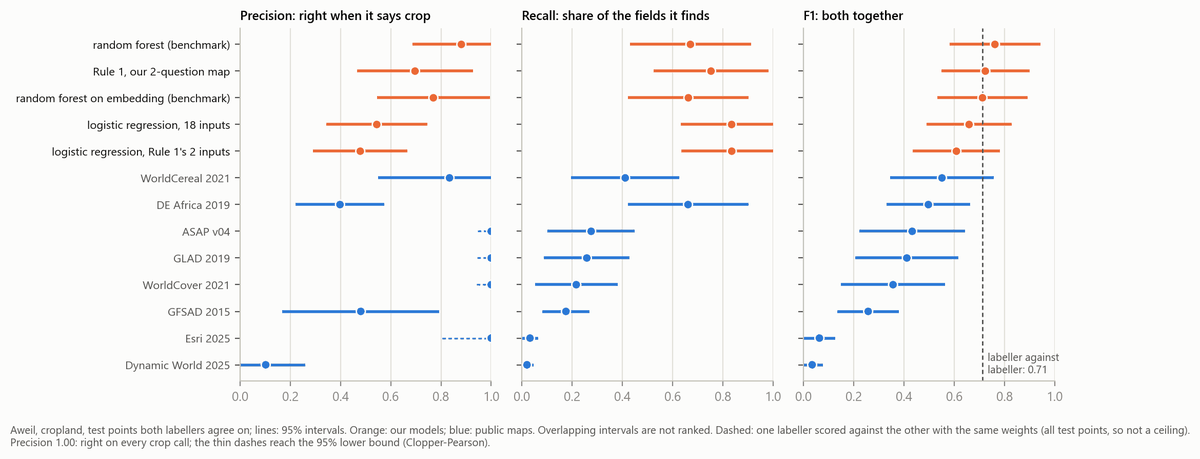

In [36]:
run("sensitivity.py")
figure("15_scorecard")

## 7. Our map over the whole country (`national_map.py`)

`national_map.py summary` counted our 30 m map per study area and per state from its native pixels in Earth Engine (saved: `results/rule1_map_share.csv`, `results/rule1_national_by_state.csv`). Outside the two study areas the map is **not checked**: nobody labelled there. Instead, `compare` sets it against the public maps at 20,000 random points (`national_check.py points`, saved in `national_check/candidates.csv`), and `figure` draws figure 27 from a 1 km copy (`fetch`, saved).

,state,ha,cfsam_2025_cereal_ha,map_pct,map_ha,cfsam_pct,notes
0,Central Equatoria,4308315.55,120600,6.95,299371.50,2.80,rank correlation with CFSAM 2025 (share of lan...
1,Eastern Equatoria,7302209.34,155634,4.34,317193.25,2.13,rank correlation with CFSAM 2025 (share of lan...
2,Jonglei,12191769.88,70829,3.23,393767.65,0.58,rank correlation with CFSAM 2025 (share of lan...
3,Lakes,4318580.68,186953,7.97,344345.25,4.33,rank correlation with CFSAM 2025 (share of lan...
4,Northern Bahr el Ghazal,3085190.68,111530,23.58,727425.10,3.62,rank correlation with CFSAM 2025 (share of lan...
5,Unity,3705893.49,19698,9.00,333377.87,0.53,rank correlation with CFSAM 2025 (share of lan...
6,Upper Nile,7723524.38,88816,4.02,310105.81,1.15,rank correlation with CFSAM 2025 (share of lan...
7,Warrap,3585547.59,181463,28.04,1005556.53,5.06,rank correlation with CFSAM 2025 (share of lan...
8,Western Bahr el Ghazal,9127162.34,91504,3.63,331244.81,1.00,rank correlation with CFSAM 2025 (share of lan...
9,Western Equatoria,7891320.80,196380,2.73,215619.55,2.49,rank correlation with CFSAM 2025 (share of lan...


                              state  points  ours_pct  any_public_pct  ours_marks_of_any_public_pct  ours_marks_of_two_public_pct  any_public_of_ours_pct
South Sudan without the study areas   20000       5.7             5.5                          21.4                          29.5                    20.5
                       Abyei Region     338       0.0             2.4                           0.0                           NaN                     NaN
                  Central Equatoria    1432       6.6             4.7                          32.8                          66.7                    23.2
                  Eastern Equatoria    2447       4.2             8.4                          10.7                           7.1                    21.4
                            Jonglei    3630       3.2             6.2                           8.4                           NaN                    16.5
                              Lakes    1442       7.8             2.6       

deliverables\cropland_report\figures\27_national_map.png
[national_map.py figure: 1 s]


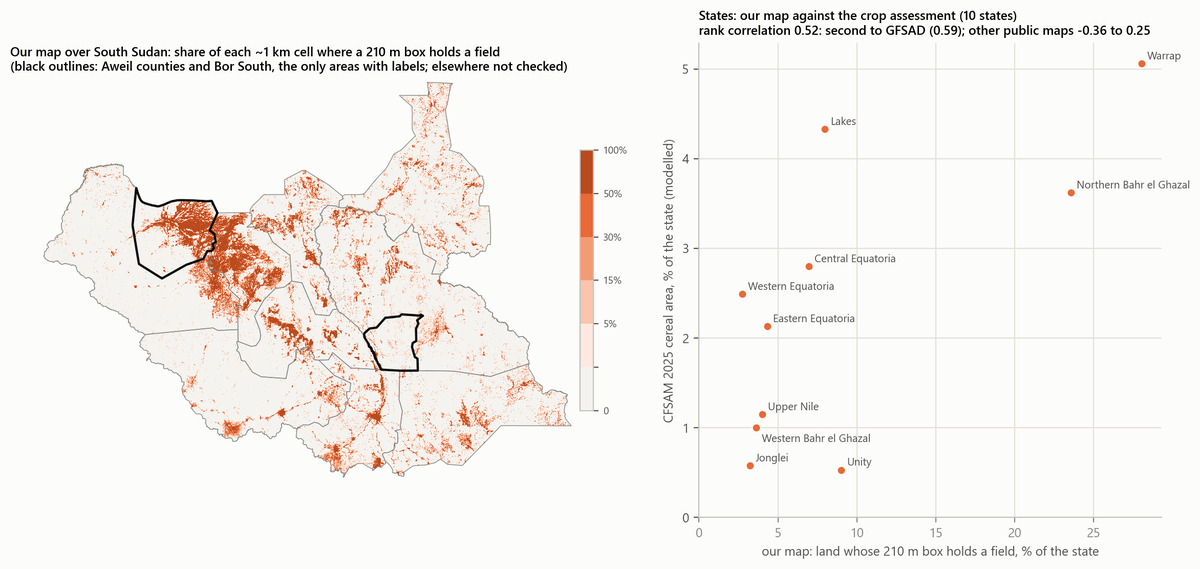

In [37]:
display(pd.read_csv(RES / "rule1_national_by_state.csv").round(3))
run("national_map.py", "compare")
run("national_map.py", "figure")
figure("27_national_map")

## 8. The dashboard

`14_dashboard.py` writes `deliverables/cropland_report/dashboard.html` from the result tables: one page with the cropland area, the maps' scores, the floods and the trigger. It opens with a double click and works offline.

In [38]:
run("14_dashboard.py")

deliverables\cropland_report\dashboard.html  (0.73 MB)
[14_dashboard.py : 1 s]


## 9. Checks

The estimators against hand-computed cases, the tree against its rules, the balance of the labeller pairs, the label merge, the model table, the config and the evaluation code. `python cropland/test_cropland.py --ee` also checks that Earth Engine applies the rules exactly as Python does.

In [39]:
run("test_cropland.py")
run("test_evaluation.py")

ok   test_area
ok   test_area_share
ok   test_accuracy_one_stratum
ok   test_area_one_point_stratum
ok   test_f1_no_cropland_found
ok   test_tree_equals_rules
ok   test_sample_pairs_balanced
4 of 4 points labelled twice; agreement on cropland vs not: 50%; 2 disagreed, 1 crop vs fallow (disagreements.csv)
           points  disagreed  crop_vs_fallow
pair                                        
Ann & Bob       4        0.5            0.25
labels_final.csv: 4 points (1 crop, 0 fallow, 0 not crop, 1 crop/fallow, 0 unsure, 2 disagreed)
model_table.csv: 0 points
ok   test_merge_no_tiebreak
ok   test_model_data_splits
ok   test_config
ok   test_linear_rules
[test_cropland.py : 0 s]


ok   test_area_interval
ok   test_coverage_simulation
ok   test_error_analysis
ok   test_trigger_agreement
ok   test_design_efficiency
ok   test_rule_complexity
[test_evaluation.py : 0 s]


## 10. The numbers in the report and on the poster

`key_results.py` collects every number the report and the poster quote from the result tables above, rounded the way each shows it (empty where one does not use it), with the file it comes from (`tables/key_results.csv`). The exposure table of 5.4 is `tables/exposure_before_after.csv`. Nothing is estimated anew here.

In [40]:
run("key_results.py")
key = pd.read_csv(OUTPUTS / "tables" / "key_results.csv")
with pd.option_context("display.max_rows", None):           # every number, not the first and last five
    display(key[["name", "what", "report", "poster", "source"]].fillna(""))
v, num = key.set_index("name").report, key.set_index("name").value
print(f"Aweil: {v.AwAreaPct} of the land is cropland ({v.AwAreaHa} ha; 95% interval {v.AwAreaLowHa} to "
      f"{round(num.AwAreaHighUsualHa, -2):,.0f} ha; adjusted upper bound {v.AwAreaHighHa} ha).")
print(f"Rule 1: F1 {v.RuleOneFone} on {v.AwTestPoints} Aweil test points; the best public map, WorldCereal 2021: {v.WorldCerealFone}.")
print(f"The 2022 flood on today's cropland in Aweil: {v.HistTwentyTwoEst} ha by the sample ({v.HistTwentyTwoLow} to "
      f"{v.HistTwentyTwoHigh}), {v.HistTwentyTwoMapsMin} to {v.HistTwentyTwoMapsMax} ha by the public maps.")

key_results.csv: 97 numbers (69 in the report, 27 on the poster); exposure_before_after.csv: 5 rows
[key_results.py : 0 s]


,name,what,report,poster,source
0,AwCropMin,"Aweil crop share, lowest public map",0.22%,0.2%,tables/key_numbers.csv
1,AwCropMax,"Aweil crop share, highest public map",1.92%,1.9%,tables/key_numbers.csv
2,WindowMin,"6 km window north of Aweil town: crop share, l...",0.0%,0,tables/window_aweil_s020.csv
3,WindowMax,"the same window: crop share, highest public map",21.7%,22%,tables/window_aweil_s020.csv
4,WindowLabelled,"the same window: labelled boxes, all holding c...",seven,,tables/window_aweil_s020.csv
5,WindowMissAll,the same window: public maps that find none of...,two,,tables/window_aweil_s020.csv
6,Window_gfsad_2015,"the same window: GFSAD's crop share, and the l...",,0.0% · 0 of 7 fields,tables/window_aweil_s020.csv
7,Window_esri_2025,"the same window: Esri's crop share, and the la...",,0.7% · 0 of 7 fields,tables/window_aweil_s020.csv
8,Window_dynamicworld_2025,"the same window: Dynamic World's crop share, a...",,3.6% · 2 of 7 fields,tables/window_aweil_s020.csv
9,Window_glad_2019,"the same window: GLAD's crop share, and the la...",,5.1% · 6 of 7 fields,tables/window_aweil_s020.csv


Aweil: 3.8% of the land is cropland (116,500 ha; 95% interval 76,700 to 156,400 ha; adjusted upper bound 183,100 ha).
Rule 1: F1 0.72 on 186 Aweil test points; the best public map, WorldCereal 2021: 0.55.
The 2022 flood on today's cropland in Aweil: 7,263 ha by the sample (639 to 14,336), 331 to 3,572 ha by the public maps.
